In [9]:
import os
import sys
root = os.path.abspath("..")
sys.path.append(root)

import io
import shutil
import pickle
import torch
import re
import json
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from datetime import datetime
from collections import defaultdict

from config import Config
from simulation.impl.trajectory_with_metrics import TrajectoryWithMetrics

if shutil.which("latex"):
    plt.style.use(["science", "ieee"])
else:
    plt.style.use(["science", "ieee", "no-latex"])

config = Config()
figures_dir = os.path.join(config.resource_dir, "figures")
os.makedirs(figures_dir, exist_ok=True)

In [10]:
class CPU_Unpickler(pickle.Unpickler):
    def find_class(self, module, name):
        if module == 'torch.storage' and name == '_load_from_bytes':
            return lambda b: torch.load(io.BytesIO(b), map_location='cpu')
        return super().find_class(module, name)

In [ ]:
TRAJECTORY_DIR = "path/to/trajectories"
EXPERIMENT_DIR = os.path.abspath("../experiments")
CLIENT_CPU_BASE = 200.0


def get_policy_label(experiment):
    policy = experiment["server_policy"]
    scale = experiment.get("server_policy_smart_priority_scale", 1.0)
    if policy == "smart" and float(scale) > 1.0:
        return "smartx"
    return policy


def load_records():
    datetimes = {}
    paths = {}
    devices = {}

    for filename in os.listdir(TRAJECTORY_DIR):
        if not filename.startswith("trajectory_exp_simulation"):
            continue
        match = re.findall(r"trajectory_exp_simulation_(.+)_(.+)_(.+)\.pkl", filename)
        if not match:
            continue
        device, idx, date_str = match[0]
        idx = int(idx)
        date_str = datetime.fromisoformat(date_str)
        if idx not in datetimes or date_str > datetimes[idx]:
            devices[idx] = device
            paths[idx] = os.path.join(TRAJECTORY_DIR, filename)
            datetimes[idx] = date_str

    records = []
    for idx, path in paths.items():
        exp_path = os.path.join(EXPERIMENT_DIR, f"exp_simulation_{devices[idx]}_{idx}.json")
        if not os.path.exists(exp_path):
            continue
        with open(exp_path) as f:
            experiment = json.load(f)
        records.append((idx, path, experiment))

    print(f"Loaded {len(records)} records")
    return records


records = load_records()

Loaded 160 records


In [12]:
POLICIES = ["centralized", "default", "smart"]  #, "smartx"]
POLICY_LABELS = ["Centralized", "Uniform", "Affinity"]  #, "SmartX"]


def fmt_clients(n):
    if n >= 1000:
        return f"{n // 1000}k"
    return str(n)

In [13]:
# key: (policy, server_mult, n_clients, client_mult, task_idx)
# value: list of (srv_rate, cli_rate)  — completed / (completed + aborted) per task
subtask_data = defaultdict(list)
n_tasks = None

for idx, path, exp in records:
    trajectory: TrajectoryWithMetrics = CPU_Unpickler(open(path, "rb")).load()

    if n_tasks is None:
        n_tasks = len(trajectory.cum_server_y_subtasks_completed)

    policy     = get_policy_label(exp)
    server_cpu = exp["available_resource_params"]["server"]["cpu"]["max"]
    client_cpu = exp["available_resource_params"]["client"]["cpu"]["max"]
    n_clients  = exp["n_clients"]

    server_mult = int(round(server_cpu / CLIENT_CPU_BASE))
    client_mult = int(round(client_cpu / CLIENT_CPU_BASE))

    srv_comp  = torch.as_tensor(trajectory.cum_server_y_subtasks_completed)
    srv_abort = torch.as_tensor(trajectory.cum_server_y_subtasks_aborted)
    cli_comp  = torch.as_tensor(trajectory.cum_client_y_subtasks_completed)
    cli_abort = torch.as_tensor(trajectory.cum_client_y_subtasks_aborted)

    for t in range(n_tasks):
        srv_total = srv_comp[t, -1] + srv_abort[t, -1]
        cli_total = cli_comp[t, -1] + cli_abort[t, -1]
        srv_rate = (srv_comp[t, -1] / srv_total).item() if srv_total > 0 else np.nan
        cli_rate = (cli_comp[t, -1] / cli_total).item() if cli_total > 0 else np.nan
        subtask_data[(policy, server_mult, n_clients, client_mult, t)].append((srv_rate, cli_rate))

TASK_LABELS = [f"Query {t + 1}" for t in range(n_tasks)]
print(f"n_tasks: {n_tasks}, unique keys: {len(subtask_data)}")

n_tasks: 4, unique keys: 640


In [14]:
server_mults = sorted({k[1] for k in subtask_data})
x_configs    = sorted({(k[2], k[3]) for k in subtask_data})
x_labels     = [f"{fmt_clients(n)}\n{m}x" for n, m in x_configs]
x_pos        = list(range(len(x_configs)))

/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_73974/4060206971.py:22: RuntimeWarning: Mean of empty slice
  cli_rate_vals.append(np.nanmean([e[1] for e in entries]))


Server completion rate — Figure 1 — server 10x  →  server_subtask_rate_10x.pdf


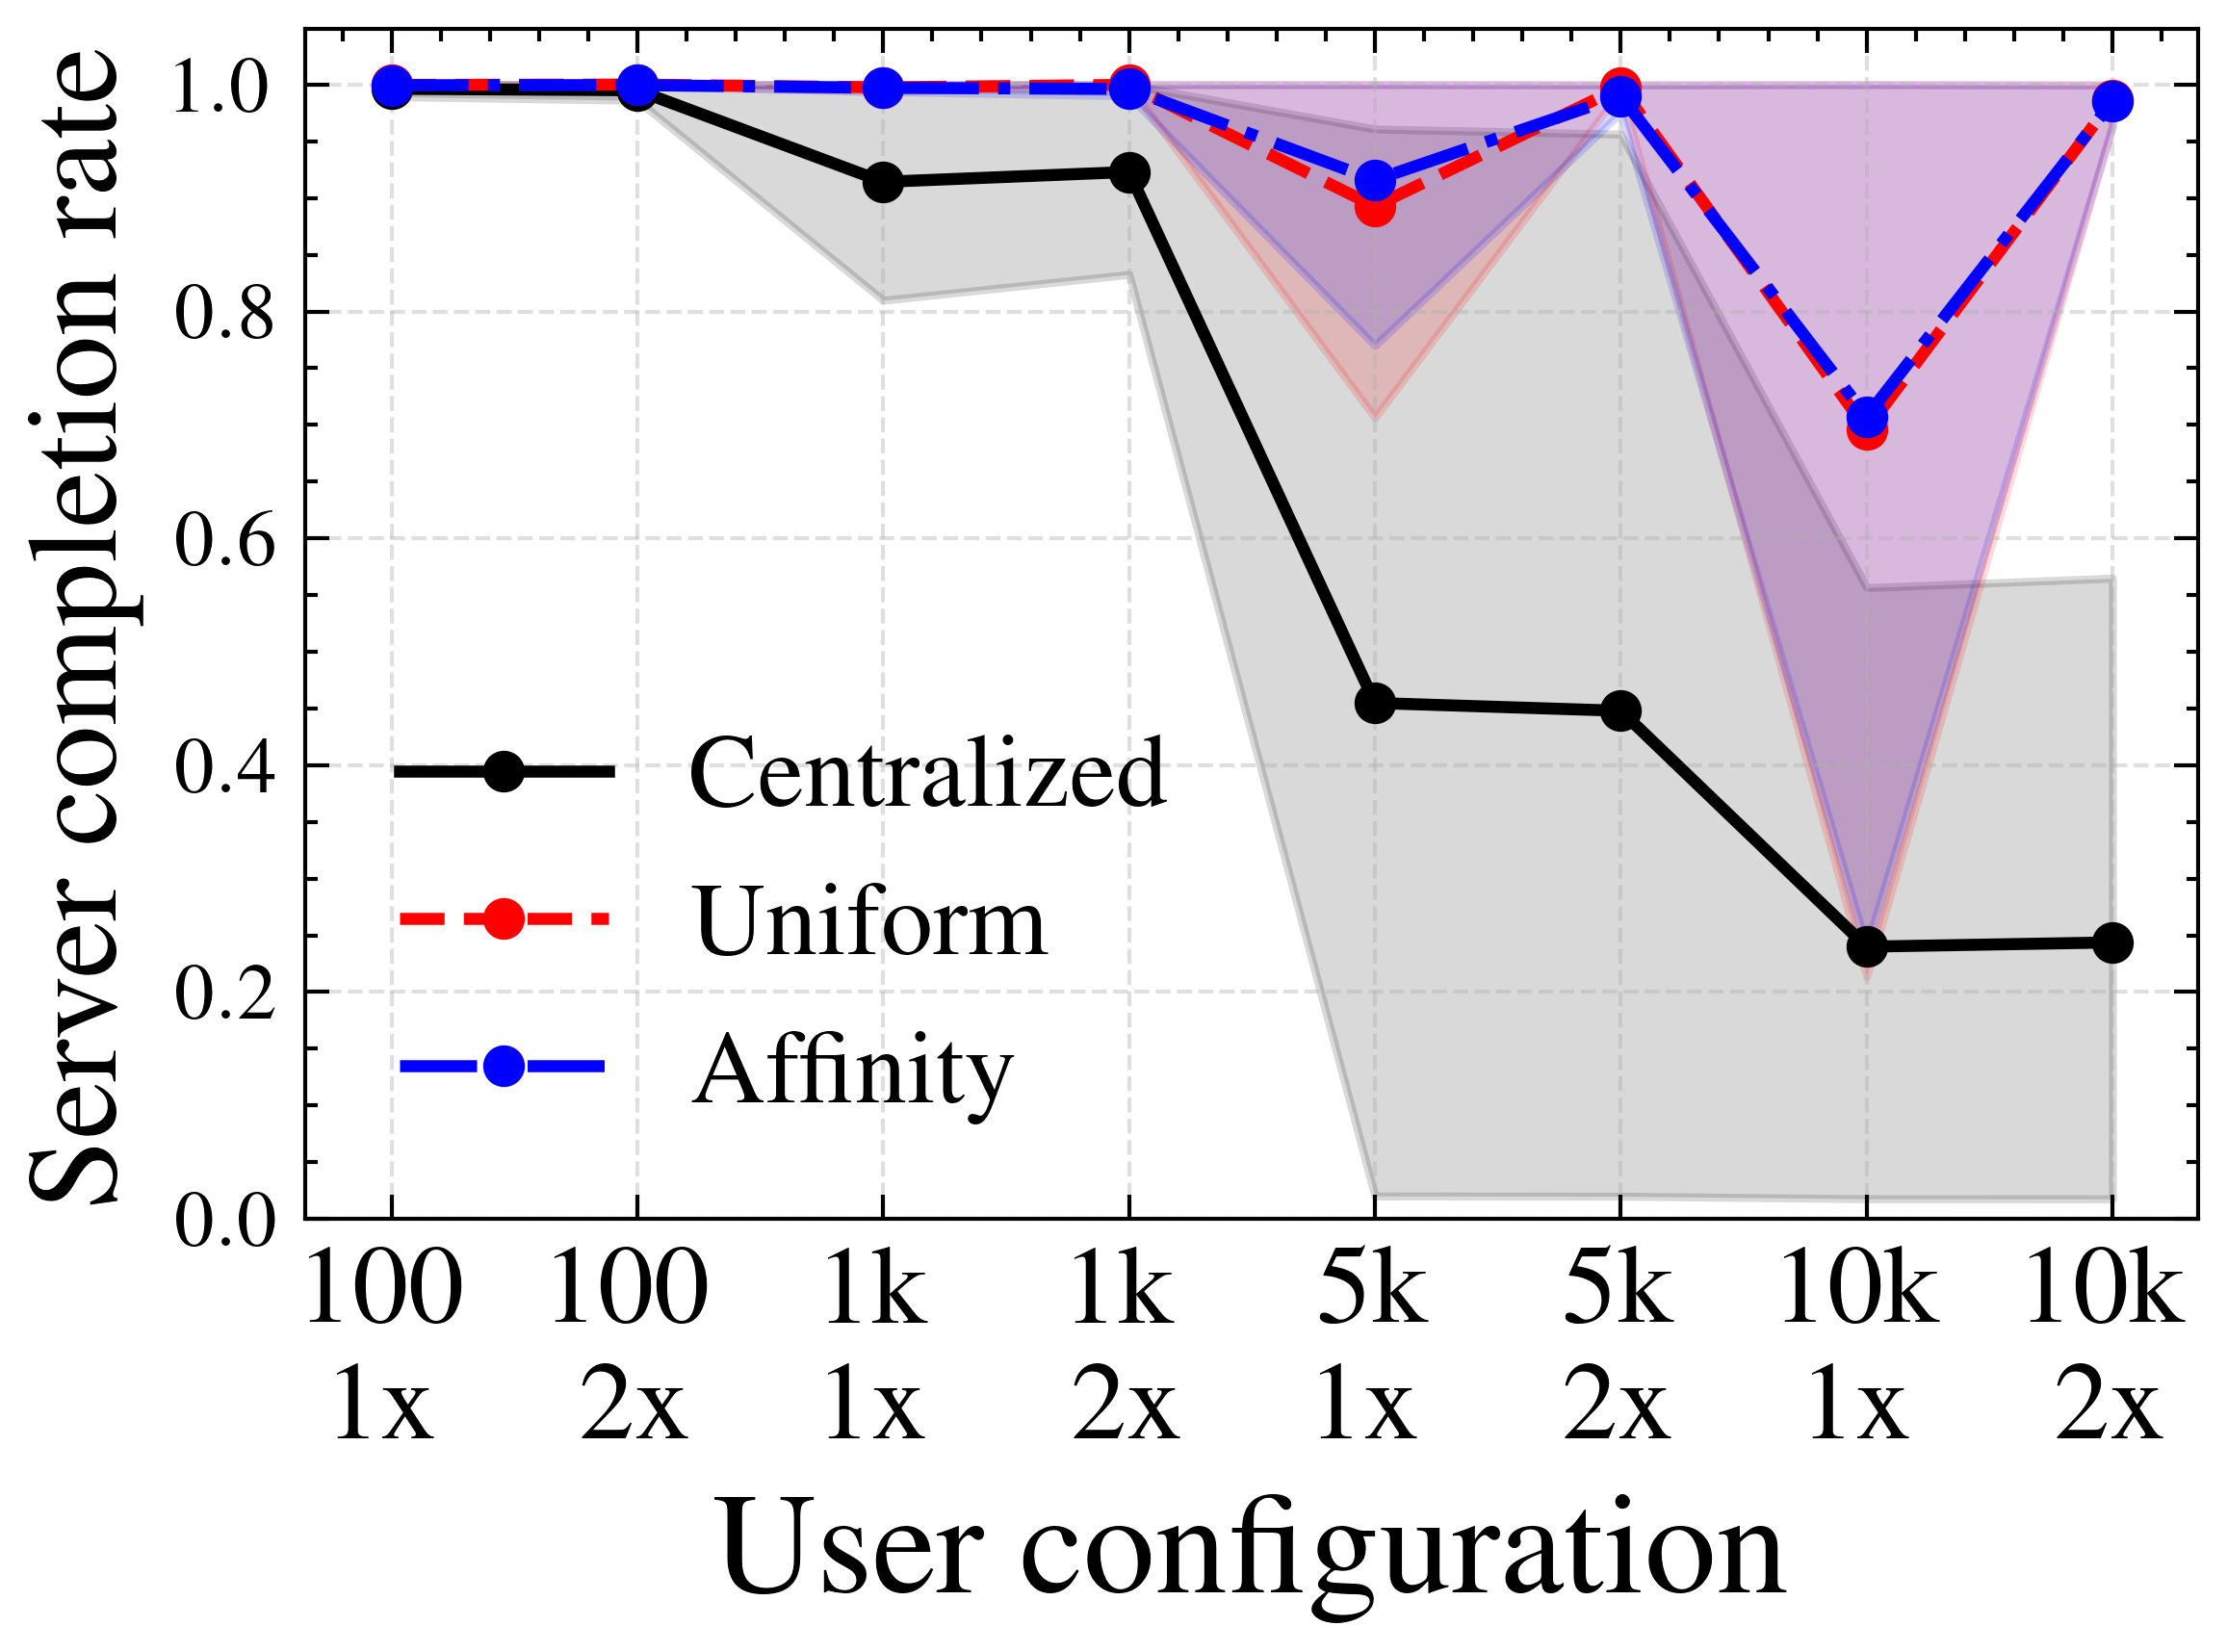

/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_73974/4060206971.py:114: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Server completion rate — Figure 2 — server 30x  →  server_subtask_rate_30x.pdf


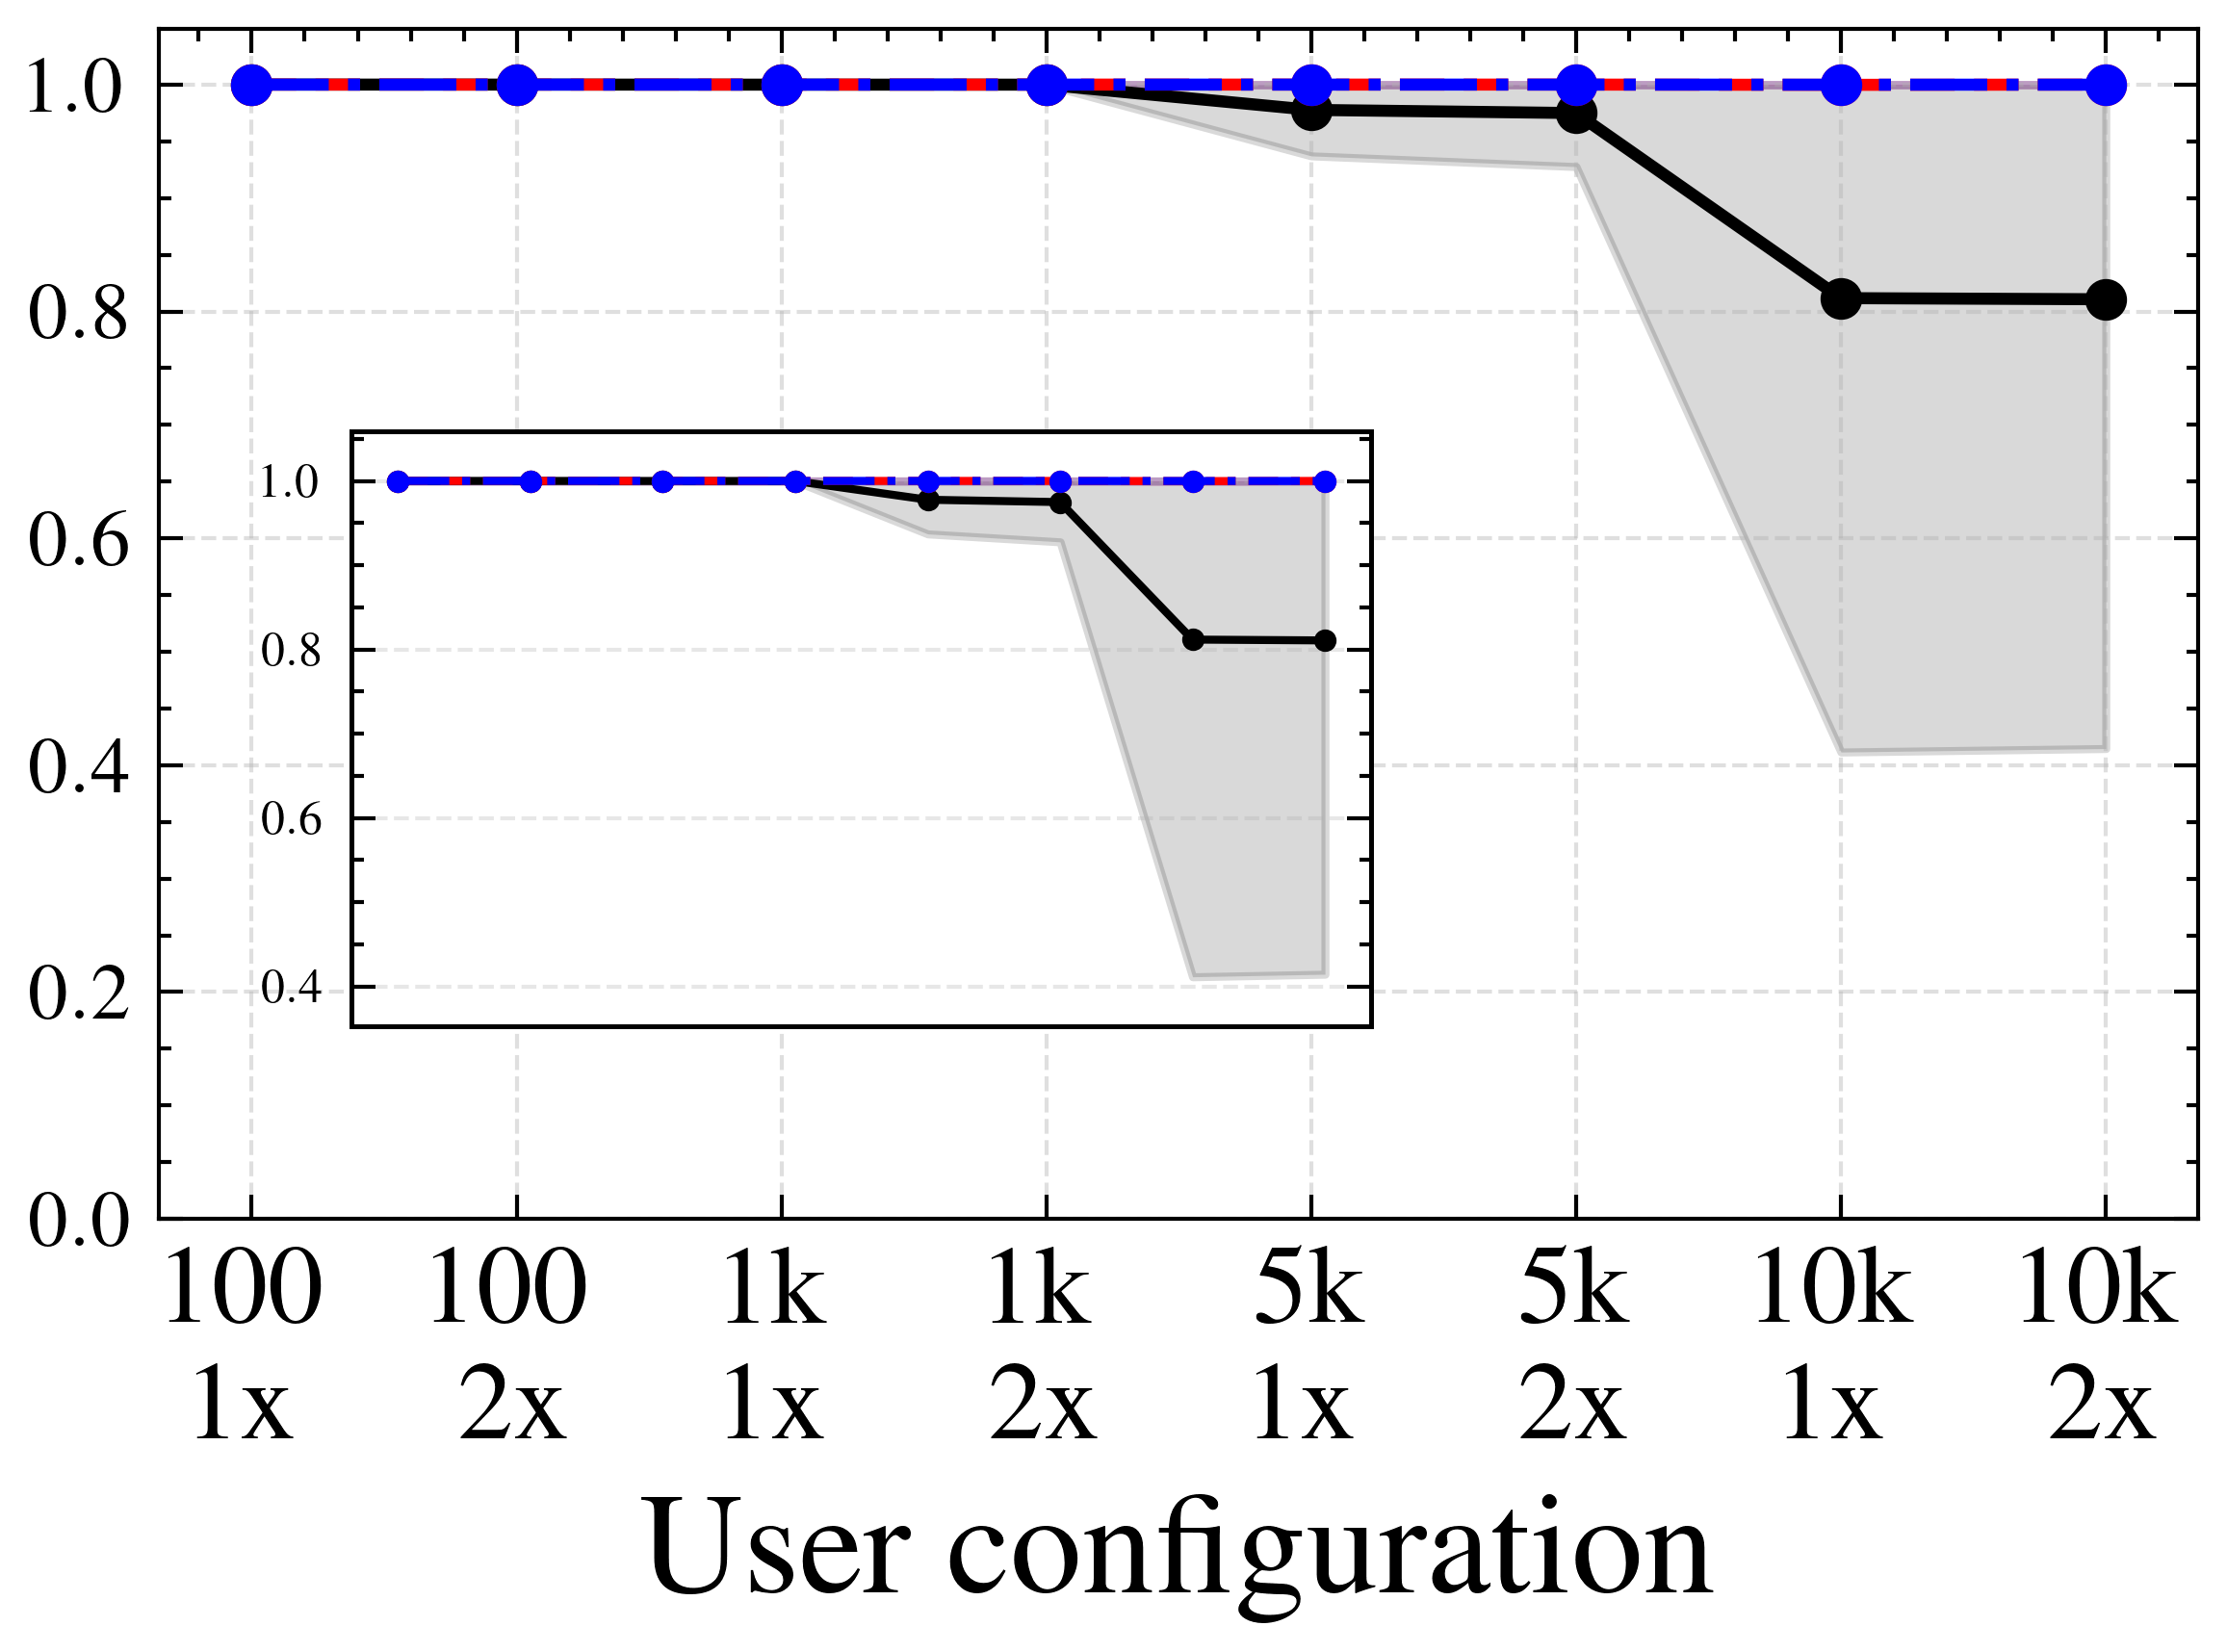

/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_73974/4060206971.py:114: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Server completion rate — Figure 3 — server 50x  →  server_subtask_rate_50x.pdf


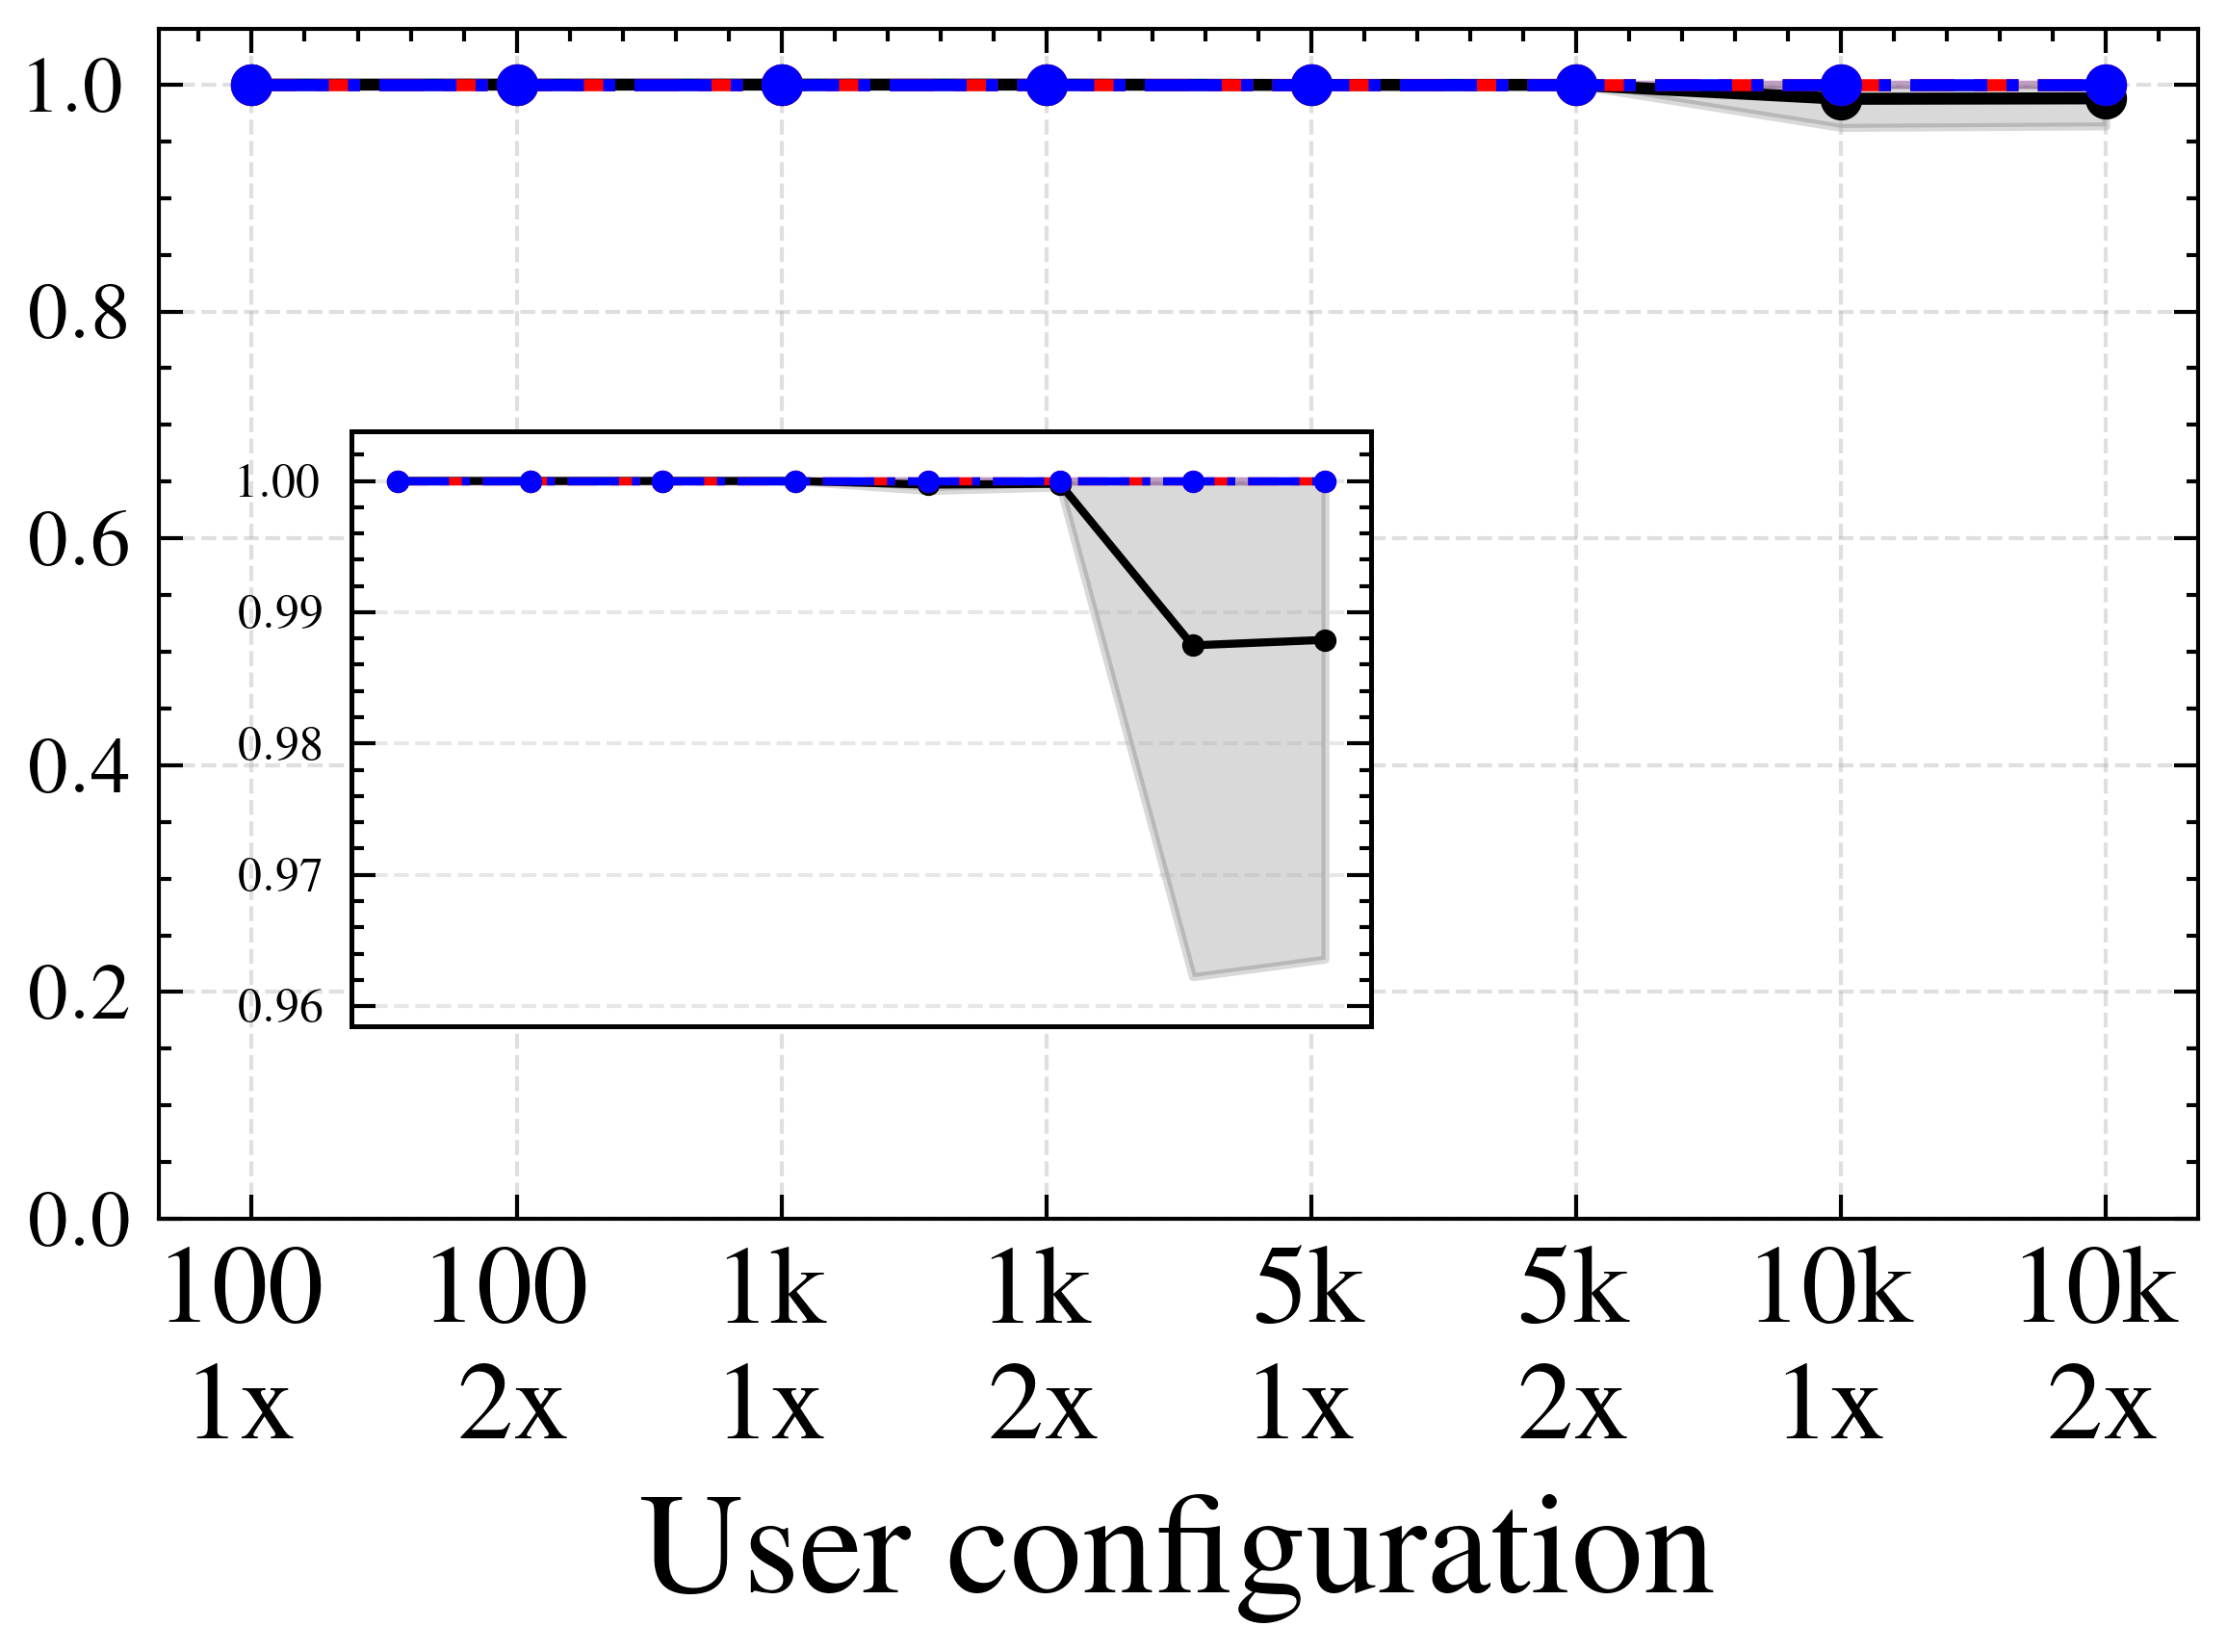

/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_73974/4060206971.py:114: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Server completion rate — Figure 4 — server 80x  →  server_subtask_rate_80x.pdf


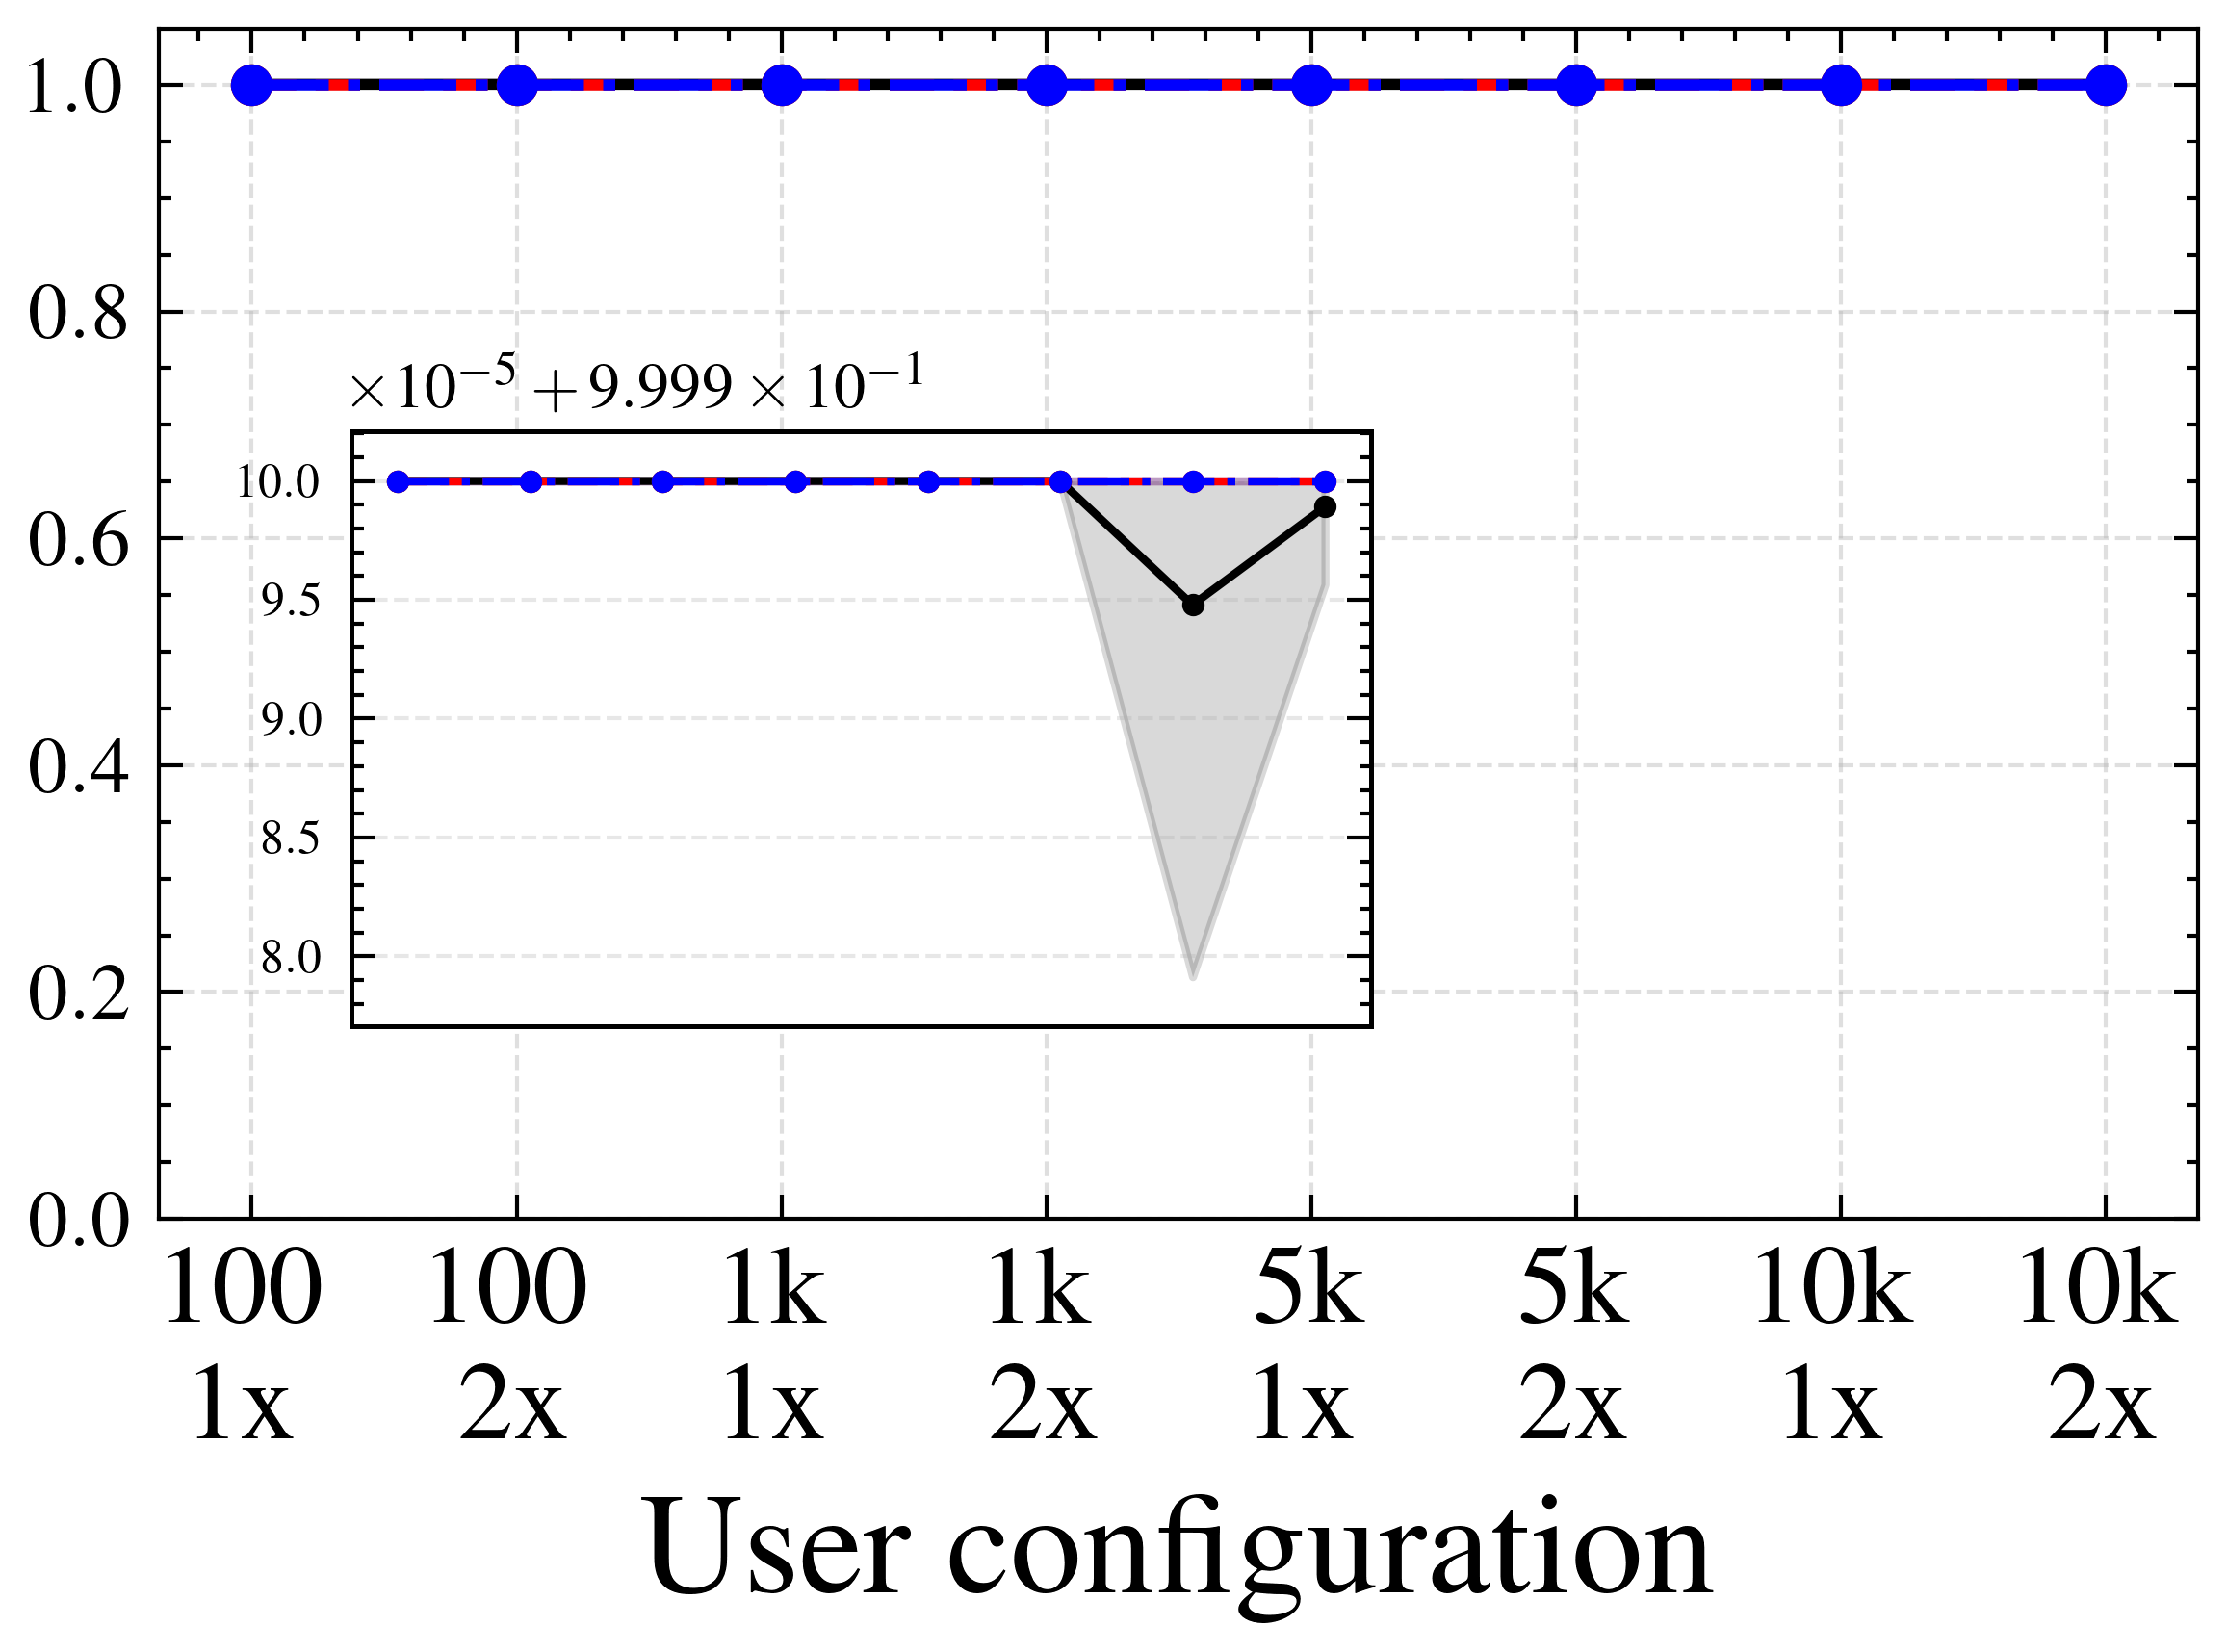

/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_73974/4060206971.py:114: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Server completion rate — Figure 5 — server 100x  →  server_subtask_rate_100x.pdf


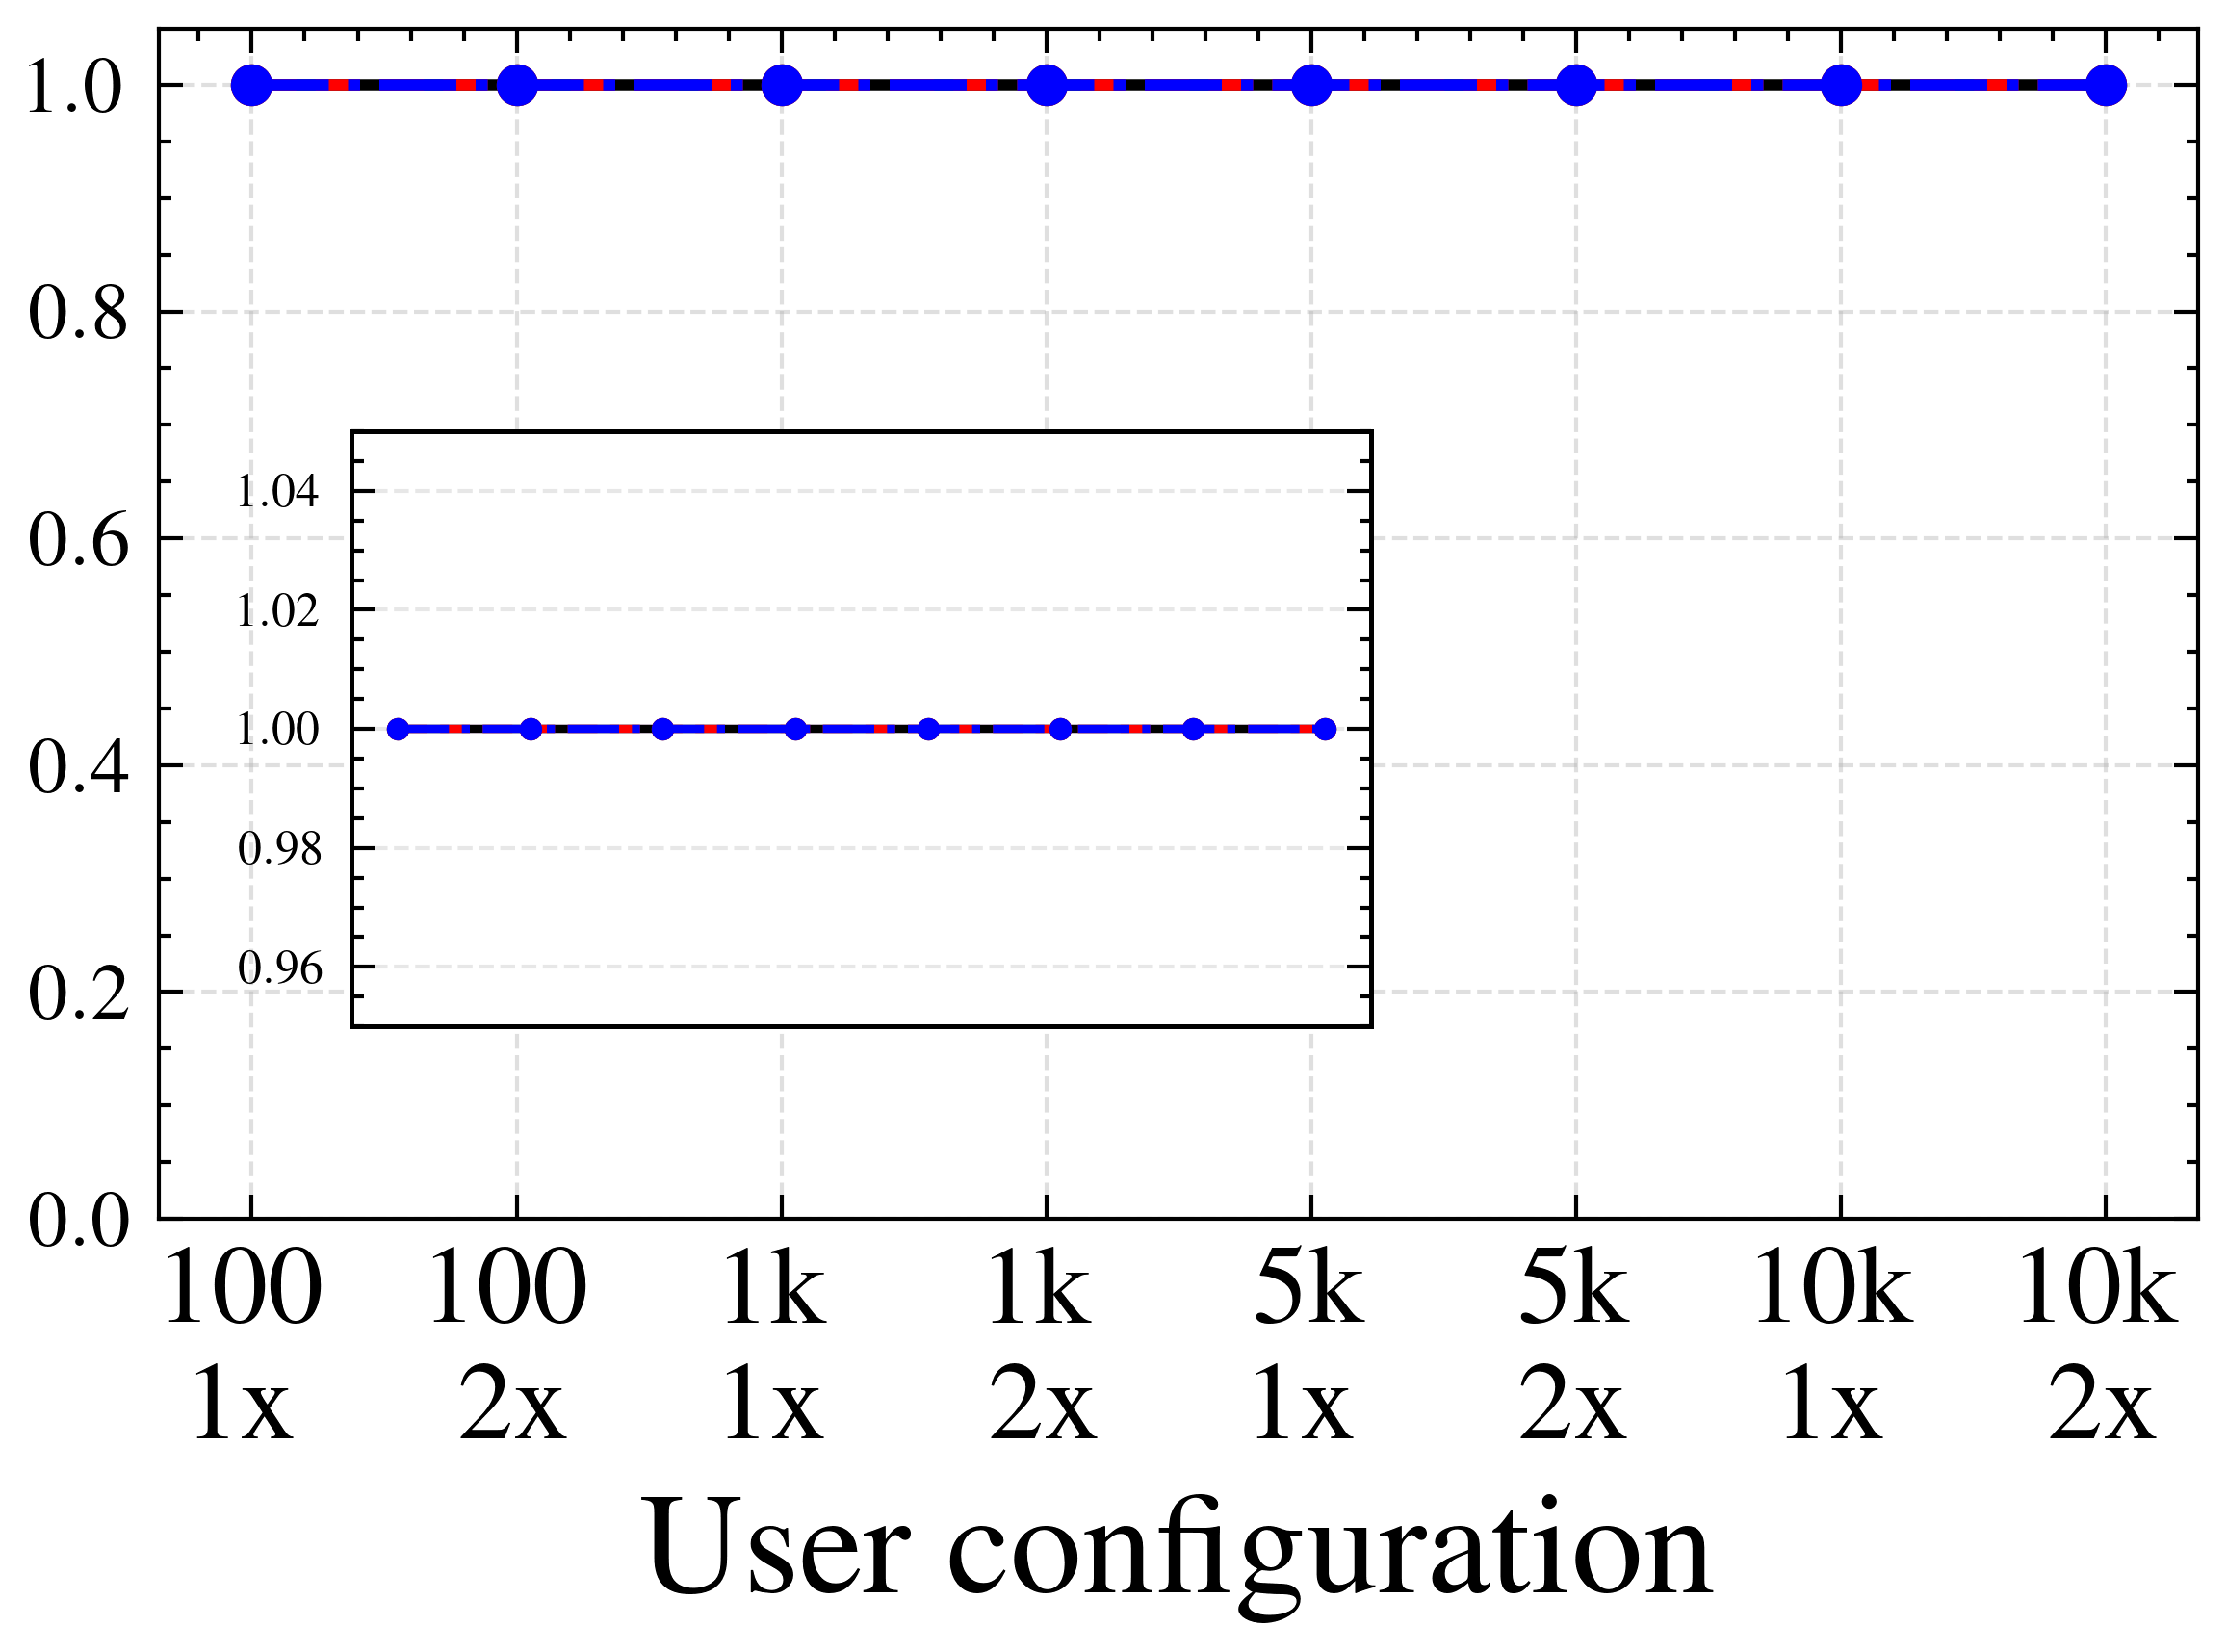

User completion rate — Figure 1 — server 10x  →  user_subtask_rate_10x.pdf

/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_73974/4060206971.py:61: RuntimeWarning: Mean of empty slice
  mean_vals  = np.nanmean(task_rates, axis=0)
/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_73974/4060206971.py:62: RuntimeWarning: All-NaN slice encountered
  min_vals   = np.nanmin(task_rates,  axis=0)
/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_73974/4060206971.py:63: RuntimeWarning: All-NaN slice encountered
  max_vals   = np.nanmax(task_rates,  axis=0)


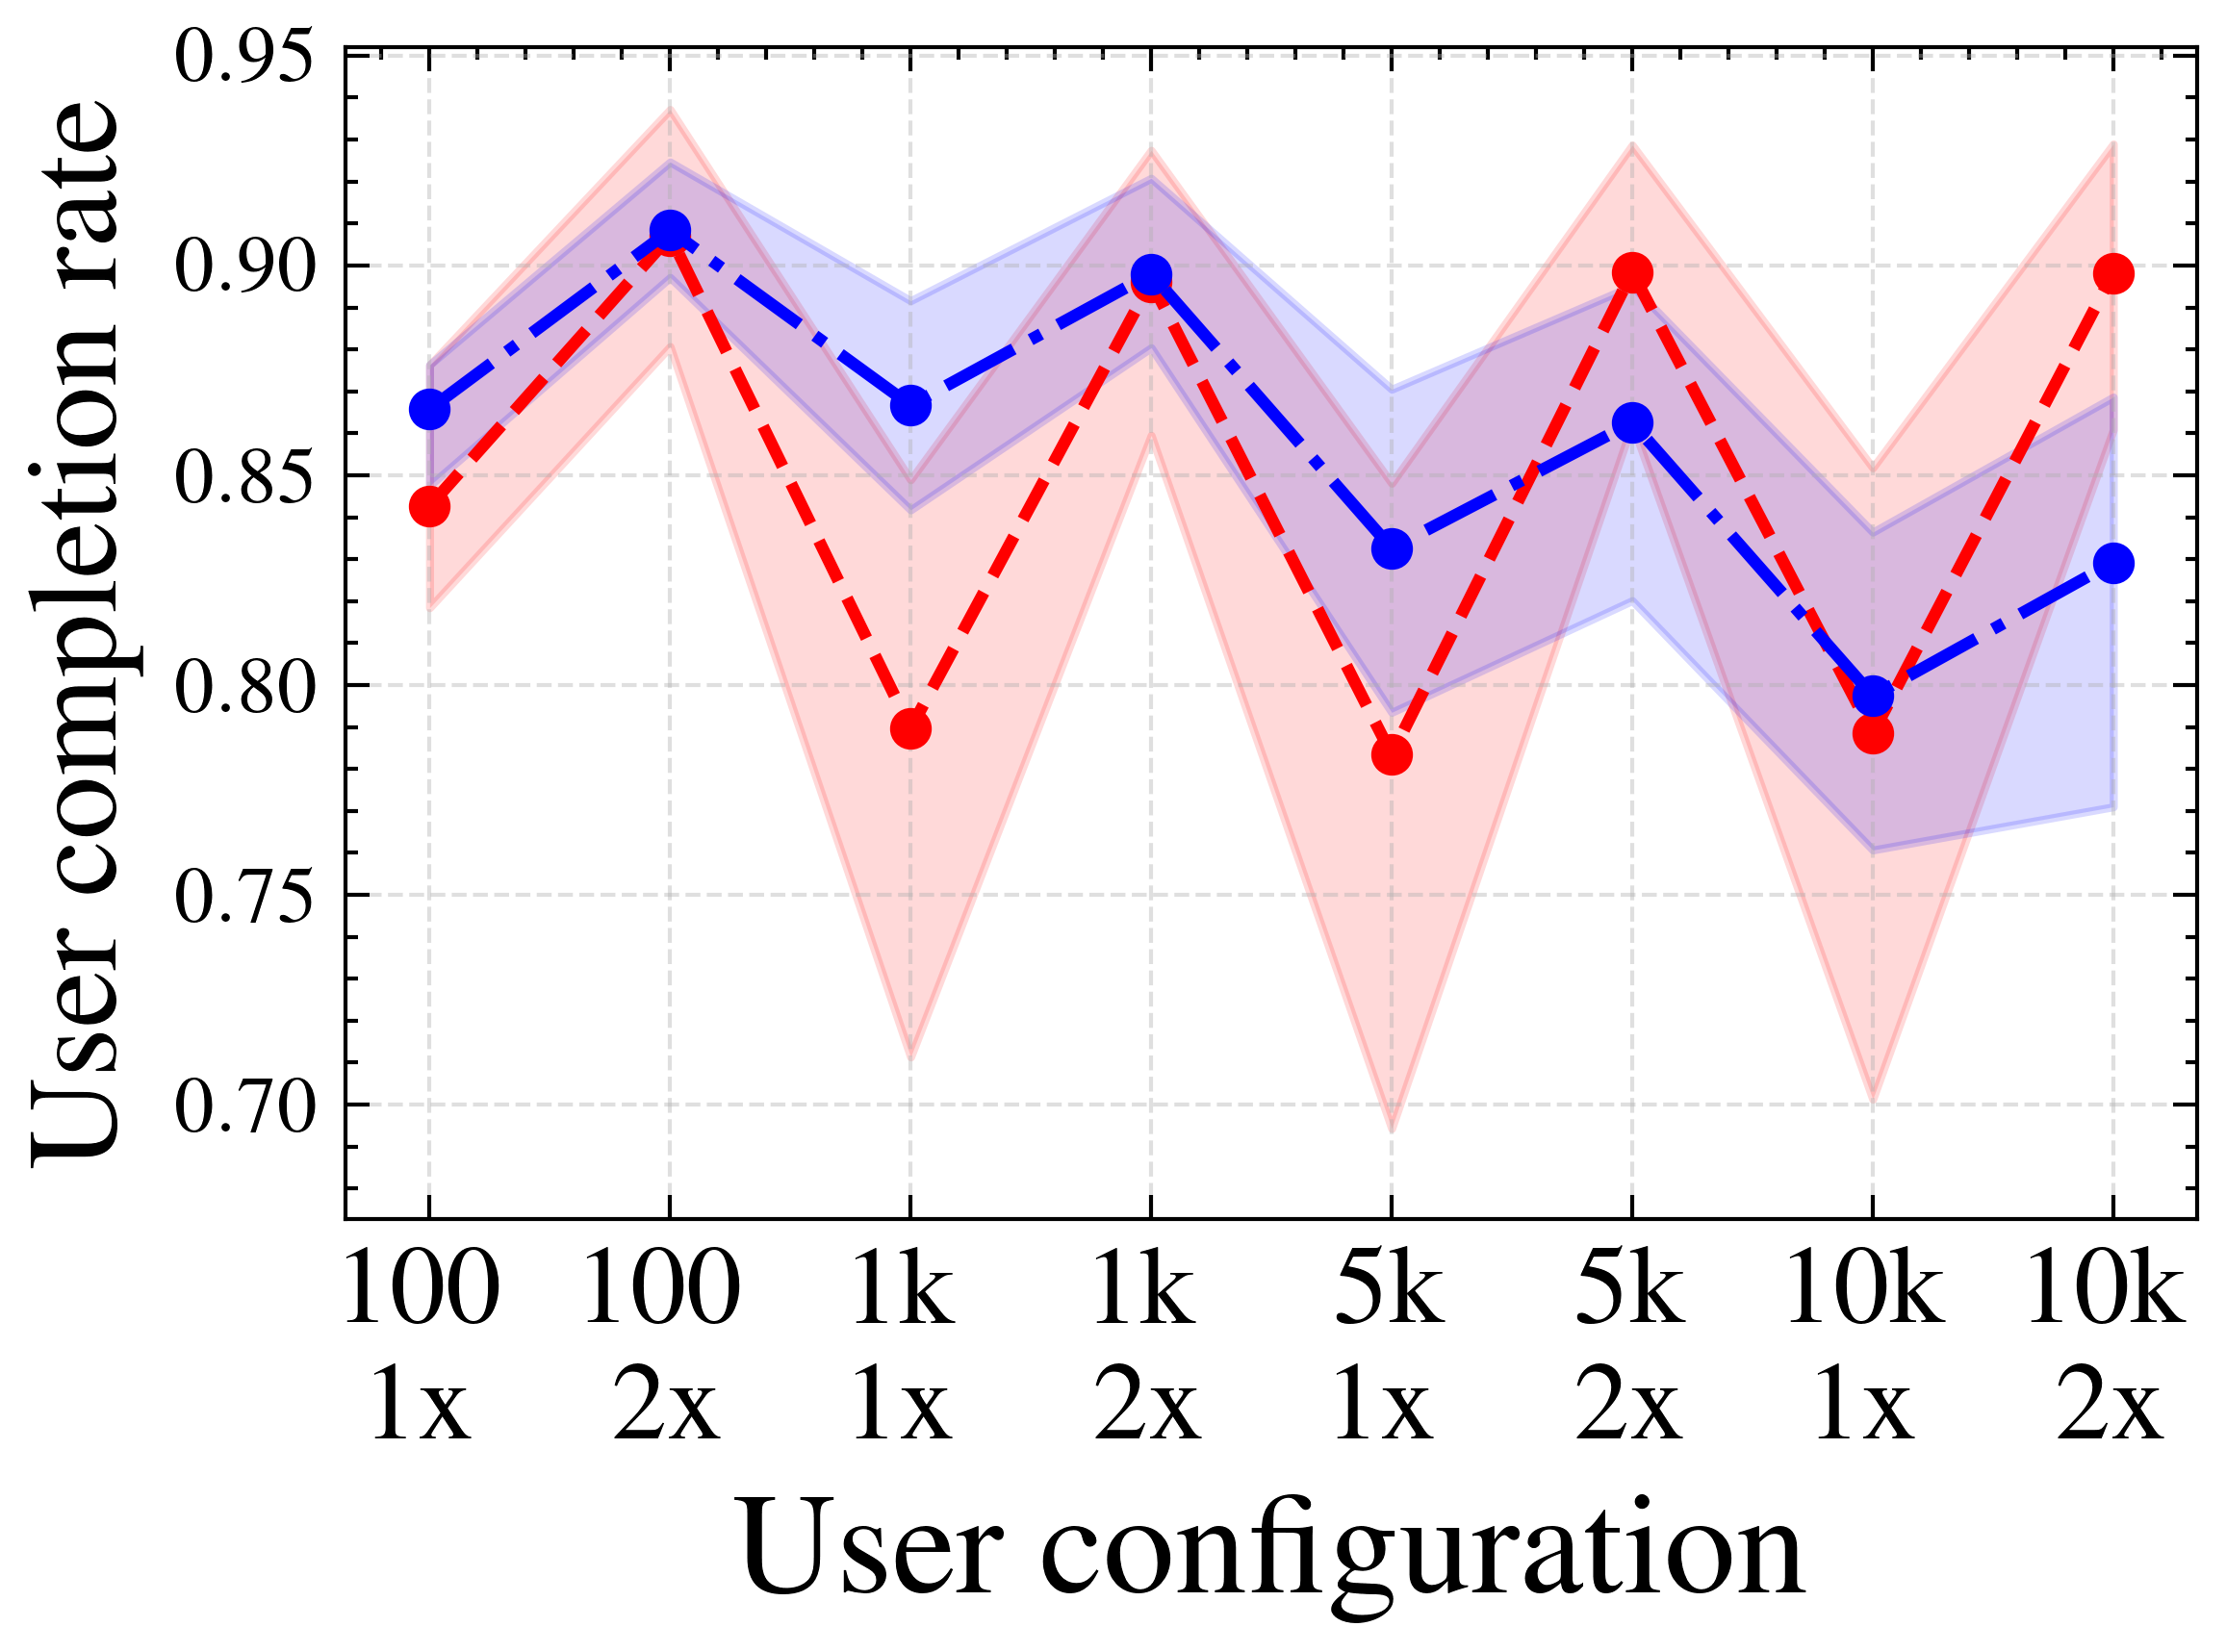

User completion rate — Figure 2 — server 30x  →  user_subtask_rate_30x.pdf


/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_73974/4060206971.py:61: RuntimeWarning: Mean of empty slice
  mean_vals  = np.nanmean(task_rates, axis=0)
/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_73974/4060206971.py:62: RuntimeWarning: All-NaN slice encountered
  min_vals   = np.nanmin(task_rates,  axis=0)
/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_73974/4060206971.py:63: RuntimeWarning: All-NaN slice encountered
  max_vals   = np.nanmax(task_rates,  axis=0)


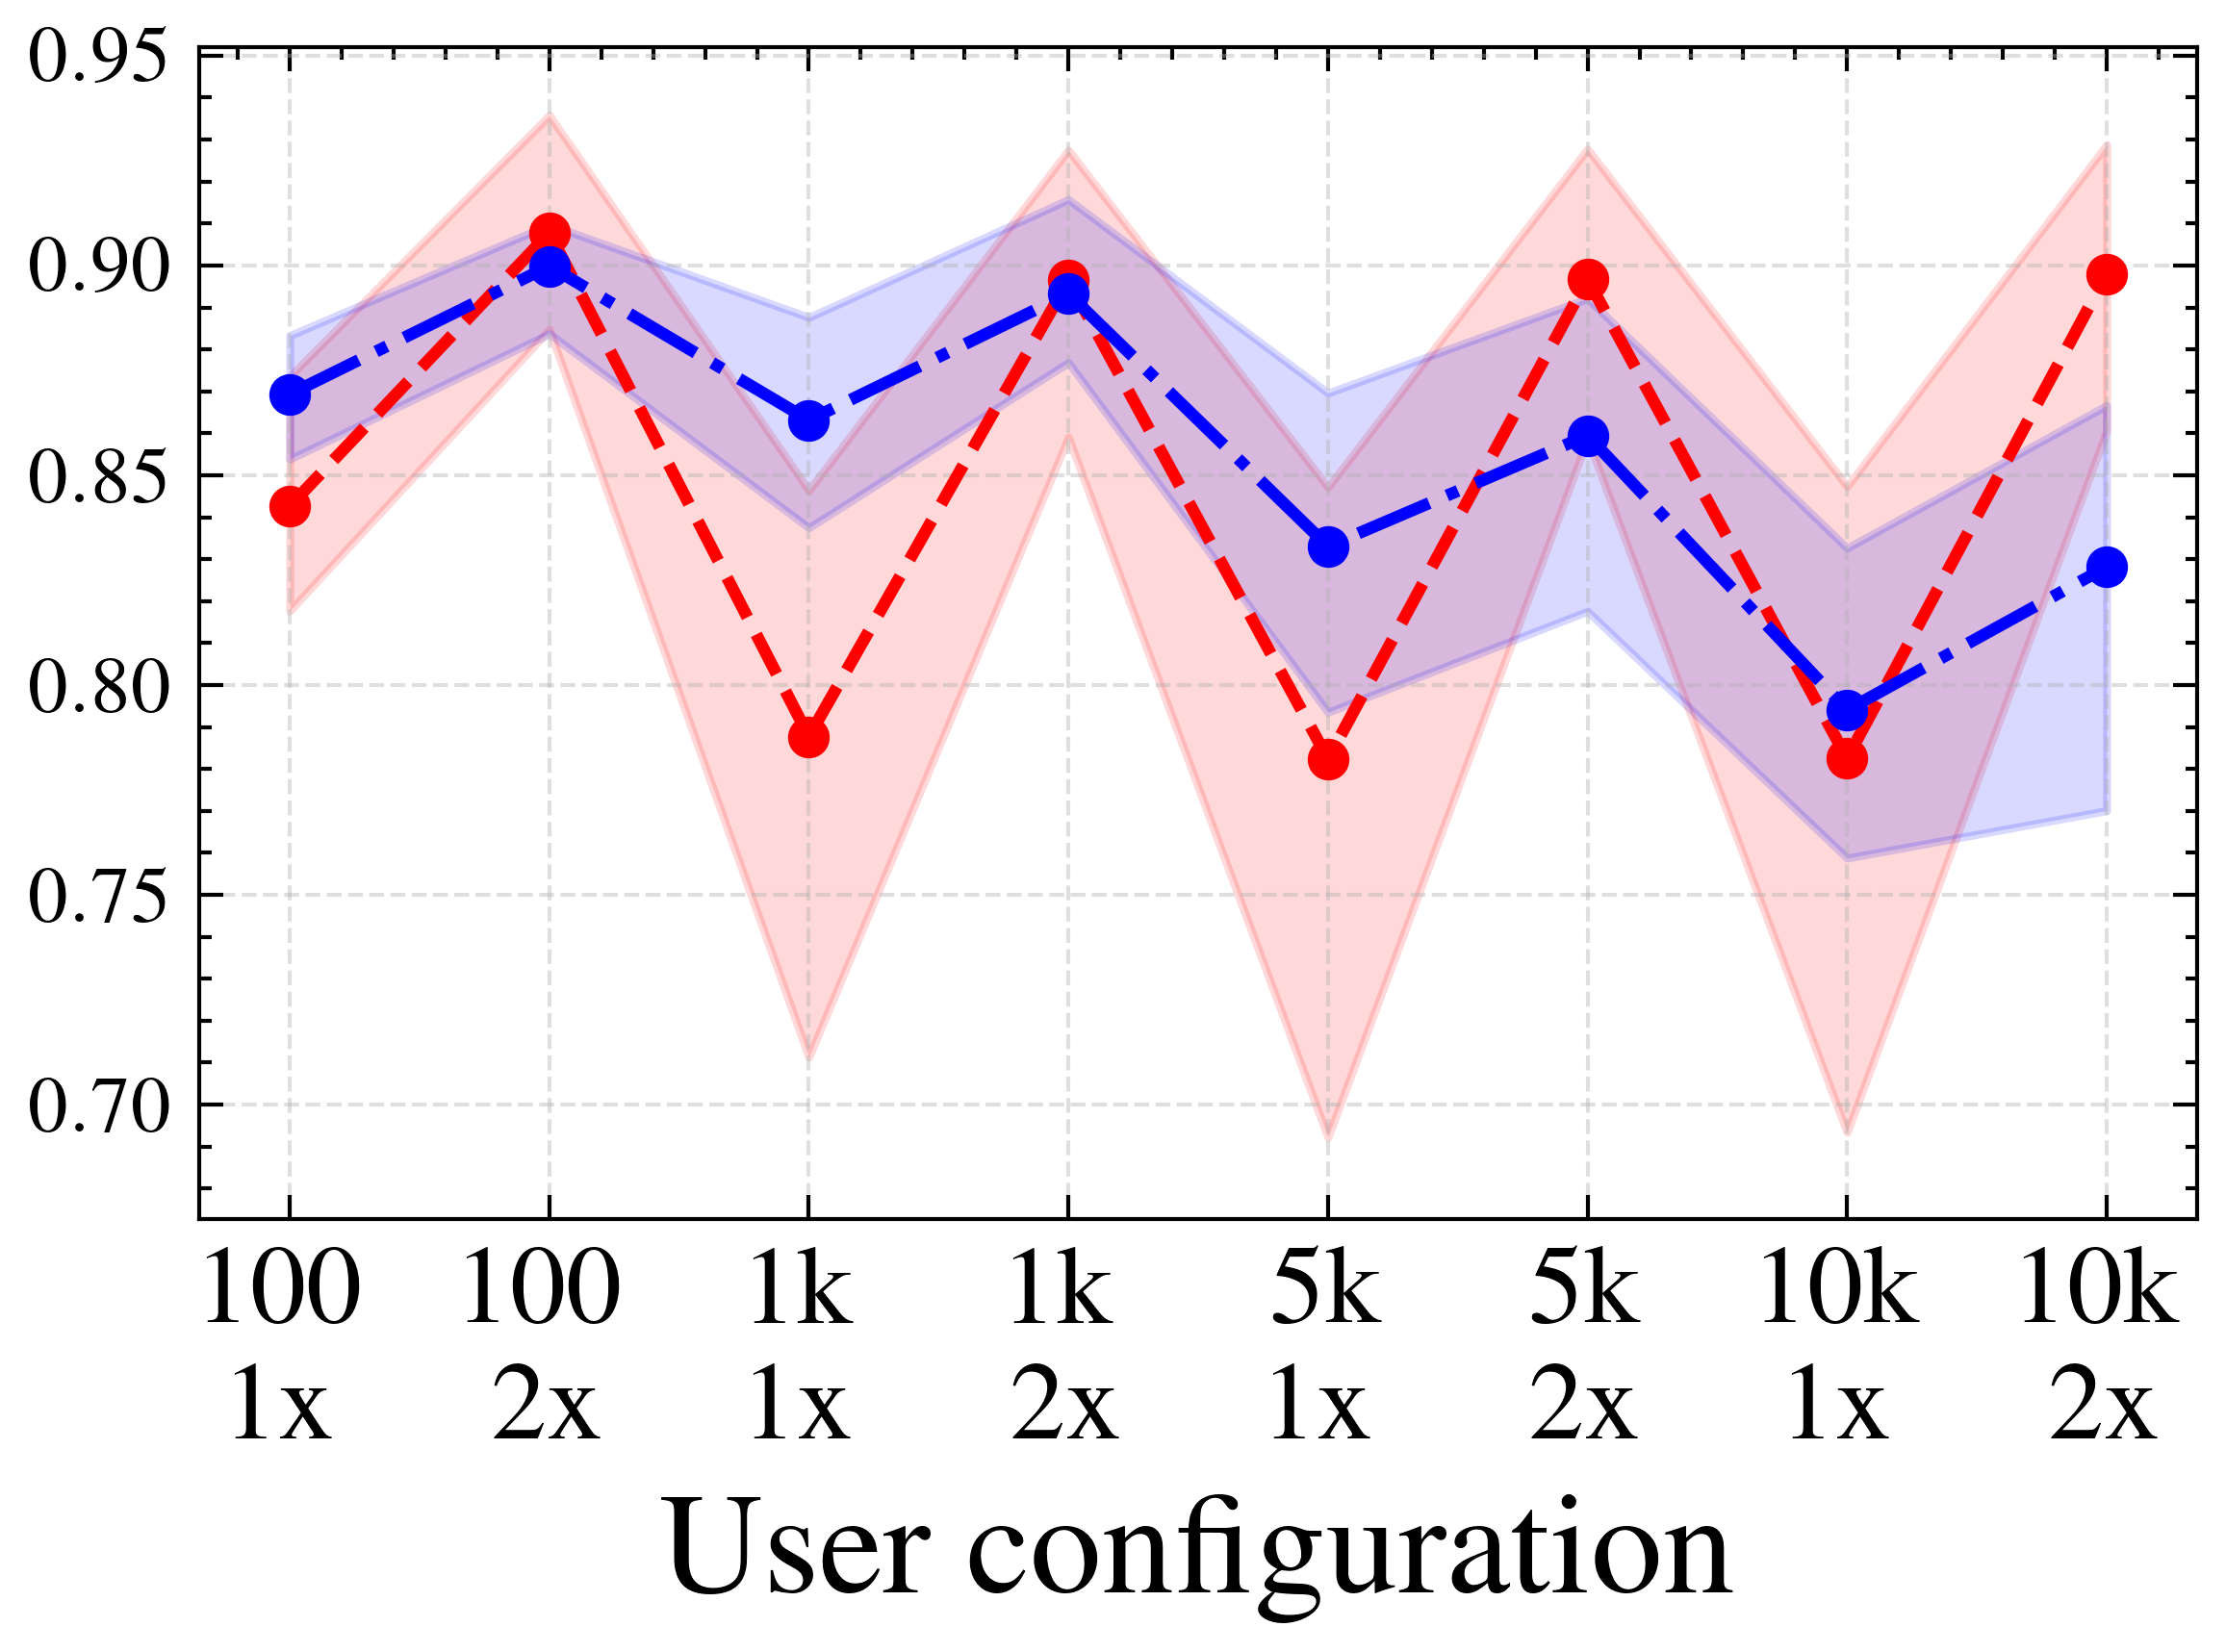

/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_73974/4060206971.py:61: RuntimeWarning: Mean of empty slice
  mean_vals  = np.nanmean(task_rates, axis=0)
/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_73974/4060206971.py:62: RuntimeWarning: All-NaN slice encountered
  min_vals   = np.nanmin(task_rates,  axis=0)
/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_73974/4060206971.py:63: RuntimeWarning: All-NaN slice encountered
  max_vals   = np.nanmax(task_rates,  axis=0)


User completion rate — Figure 3 — server 50x  →  user_subtask_rate_50x.pdf


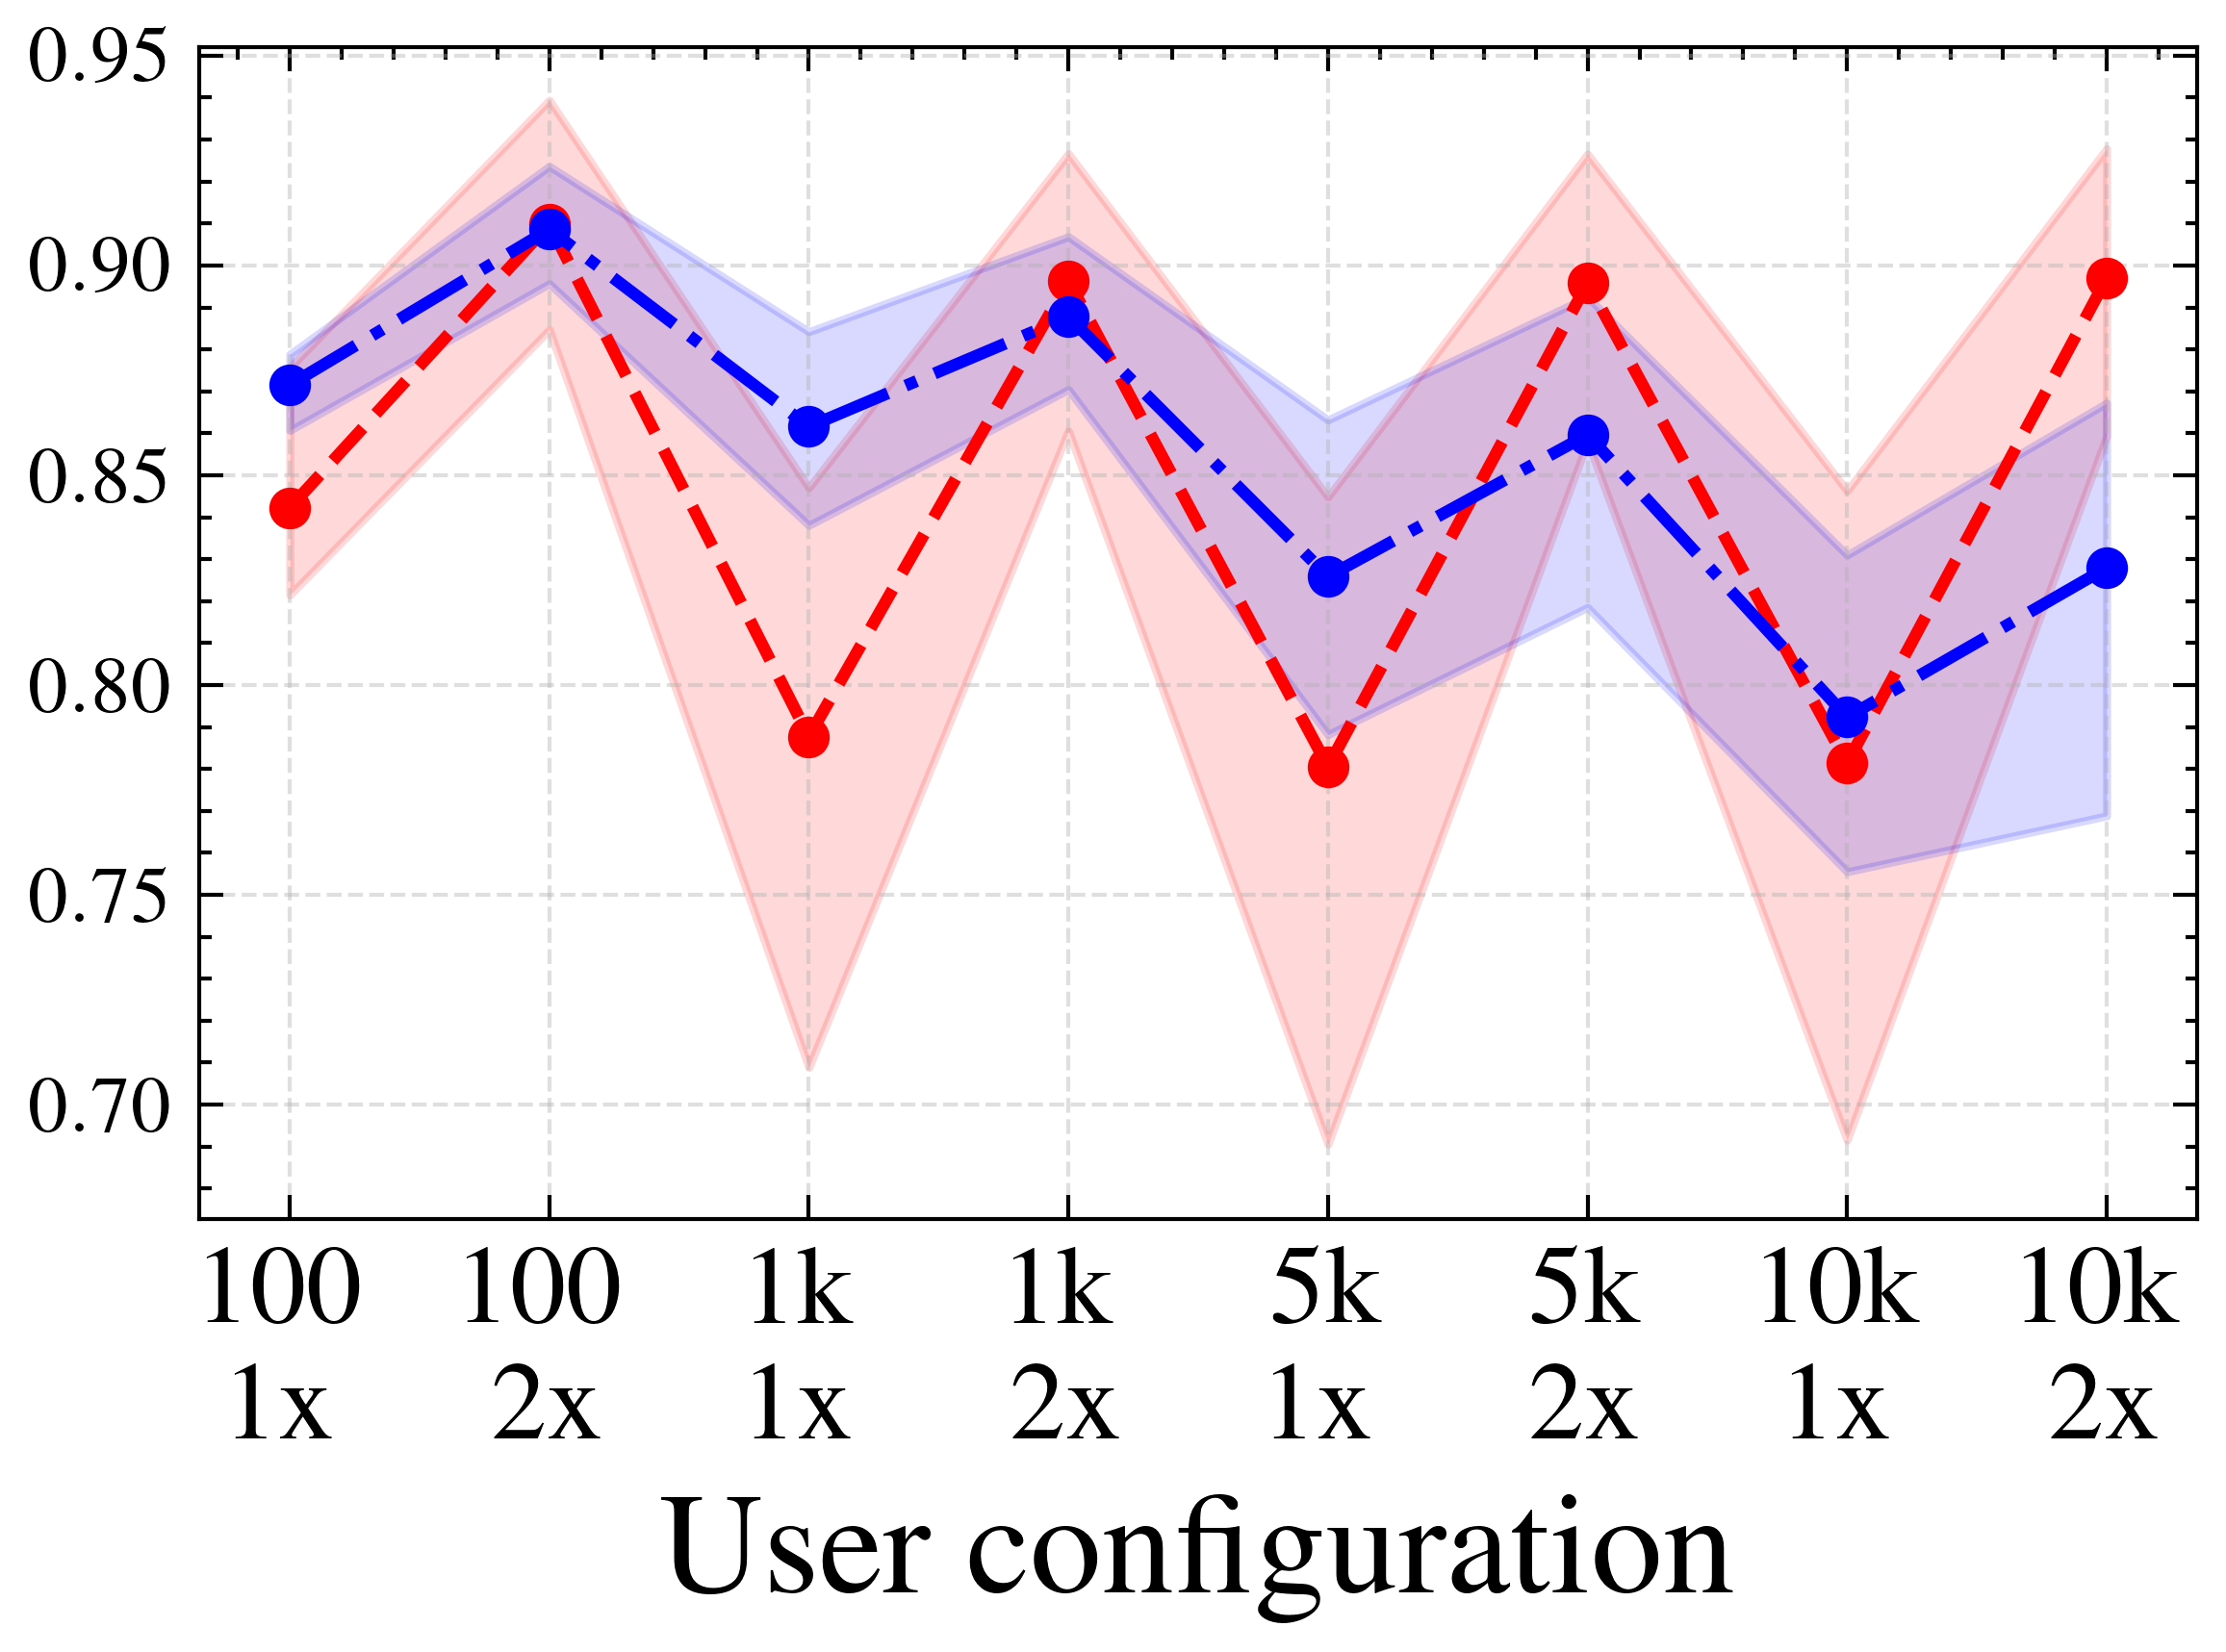

User completion rate — Figure 4 — server 80x  →  user_subtask_rate_80x.pdf


/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_73974/4060206971.py:61: RuntimeWarning: Mean of empty slice
  mean_vals  = np.nanmean(task_rates, axis=0)
/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_73974/4060206971.py:62: RuntimeWarning: All-NaN slice encountered
  min_vals   = np.nanmin(task_rates,  axis=0)
/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_73974/4060206971.py:63: RuntimeWarning: All-NaN slice encountered
  max_vals   = np.nanmax(task_rates,  axis=0)


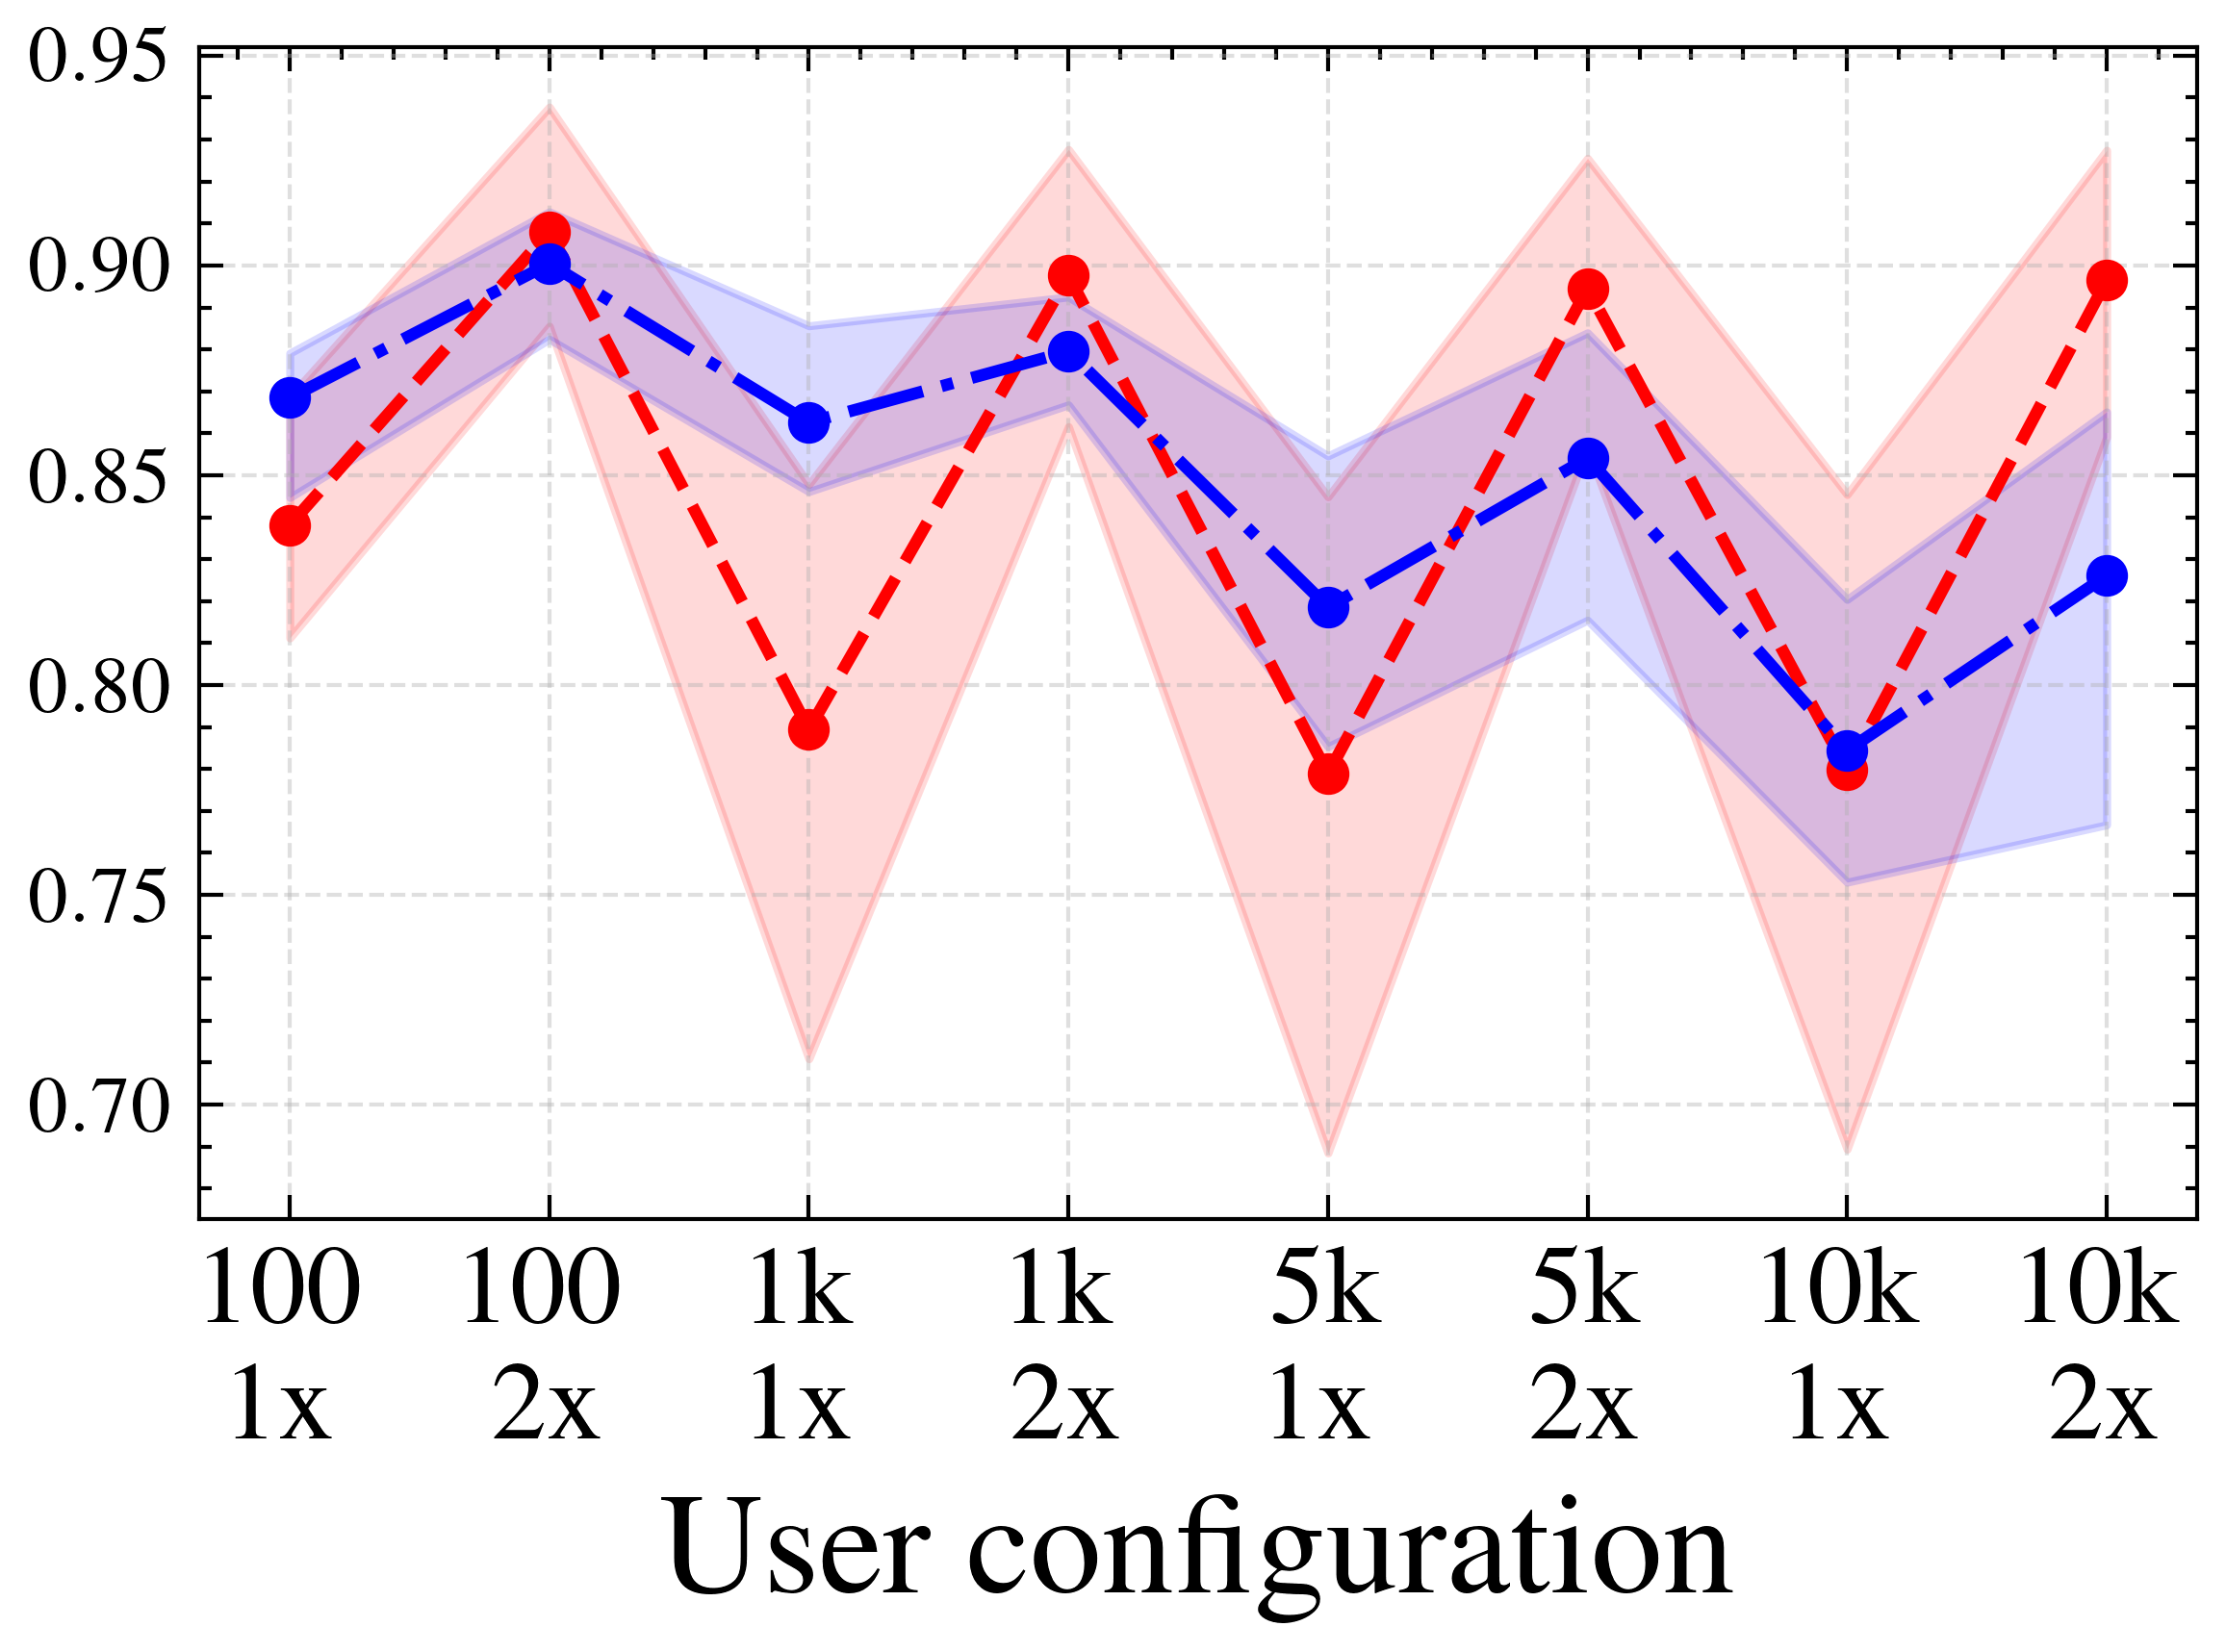

/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_73974/4060206971.py:61: RuntimeWarning: Mean of empty slice
  mean_vals  = np.nanmean(task_rates, axis=0)
/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_73974/4060206971.py:62: RuntimeWarning: All-NaN slice encountered
  min_vals   = np.nanmin(task_rates,  axis=0)
/var/folders/xw/wvvx4z1x2xz46zmp5rwx0wgc0000gp/T/ipykernel_73974/4060206971.py:63: RuntimeWarning: All-NaN slice encountered
  max_vals   = np.nanmax(task_rates,  axis=0)


User completion rate — Figure 5 — server 100x  →  user_subtask_rate_100x.pdf


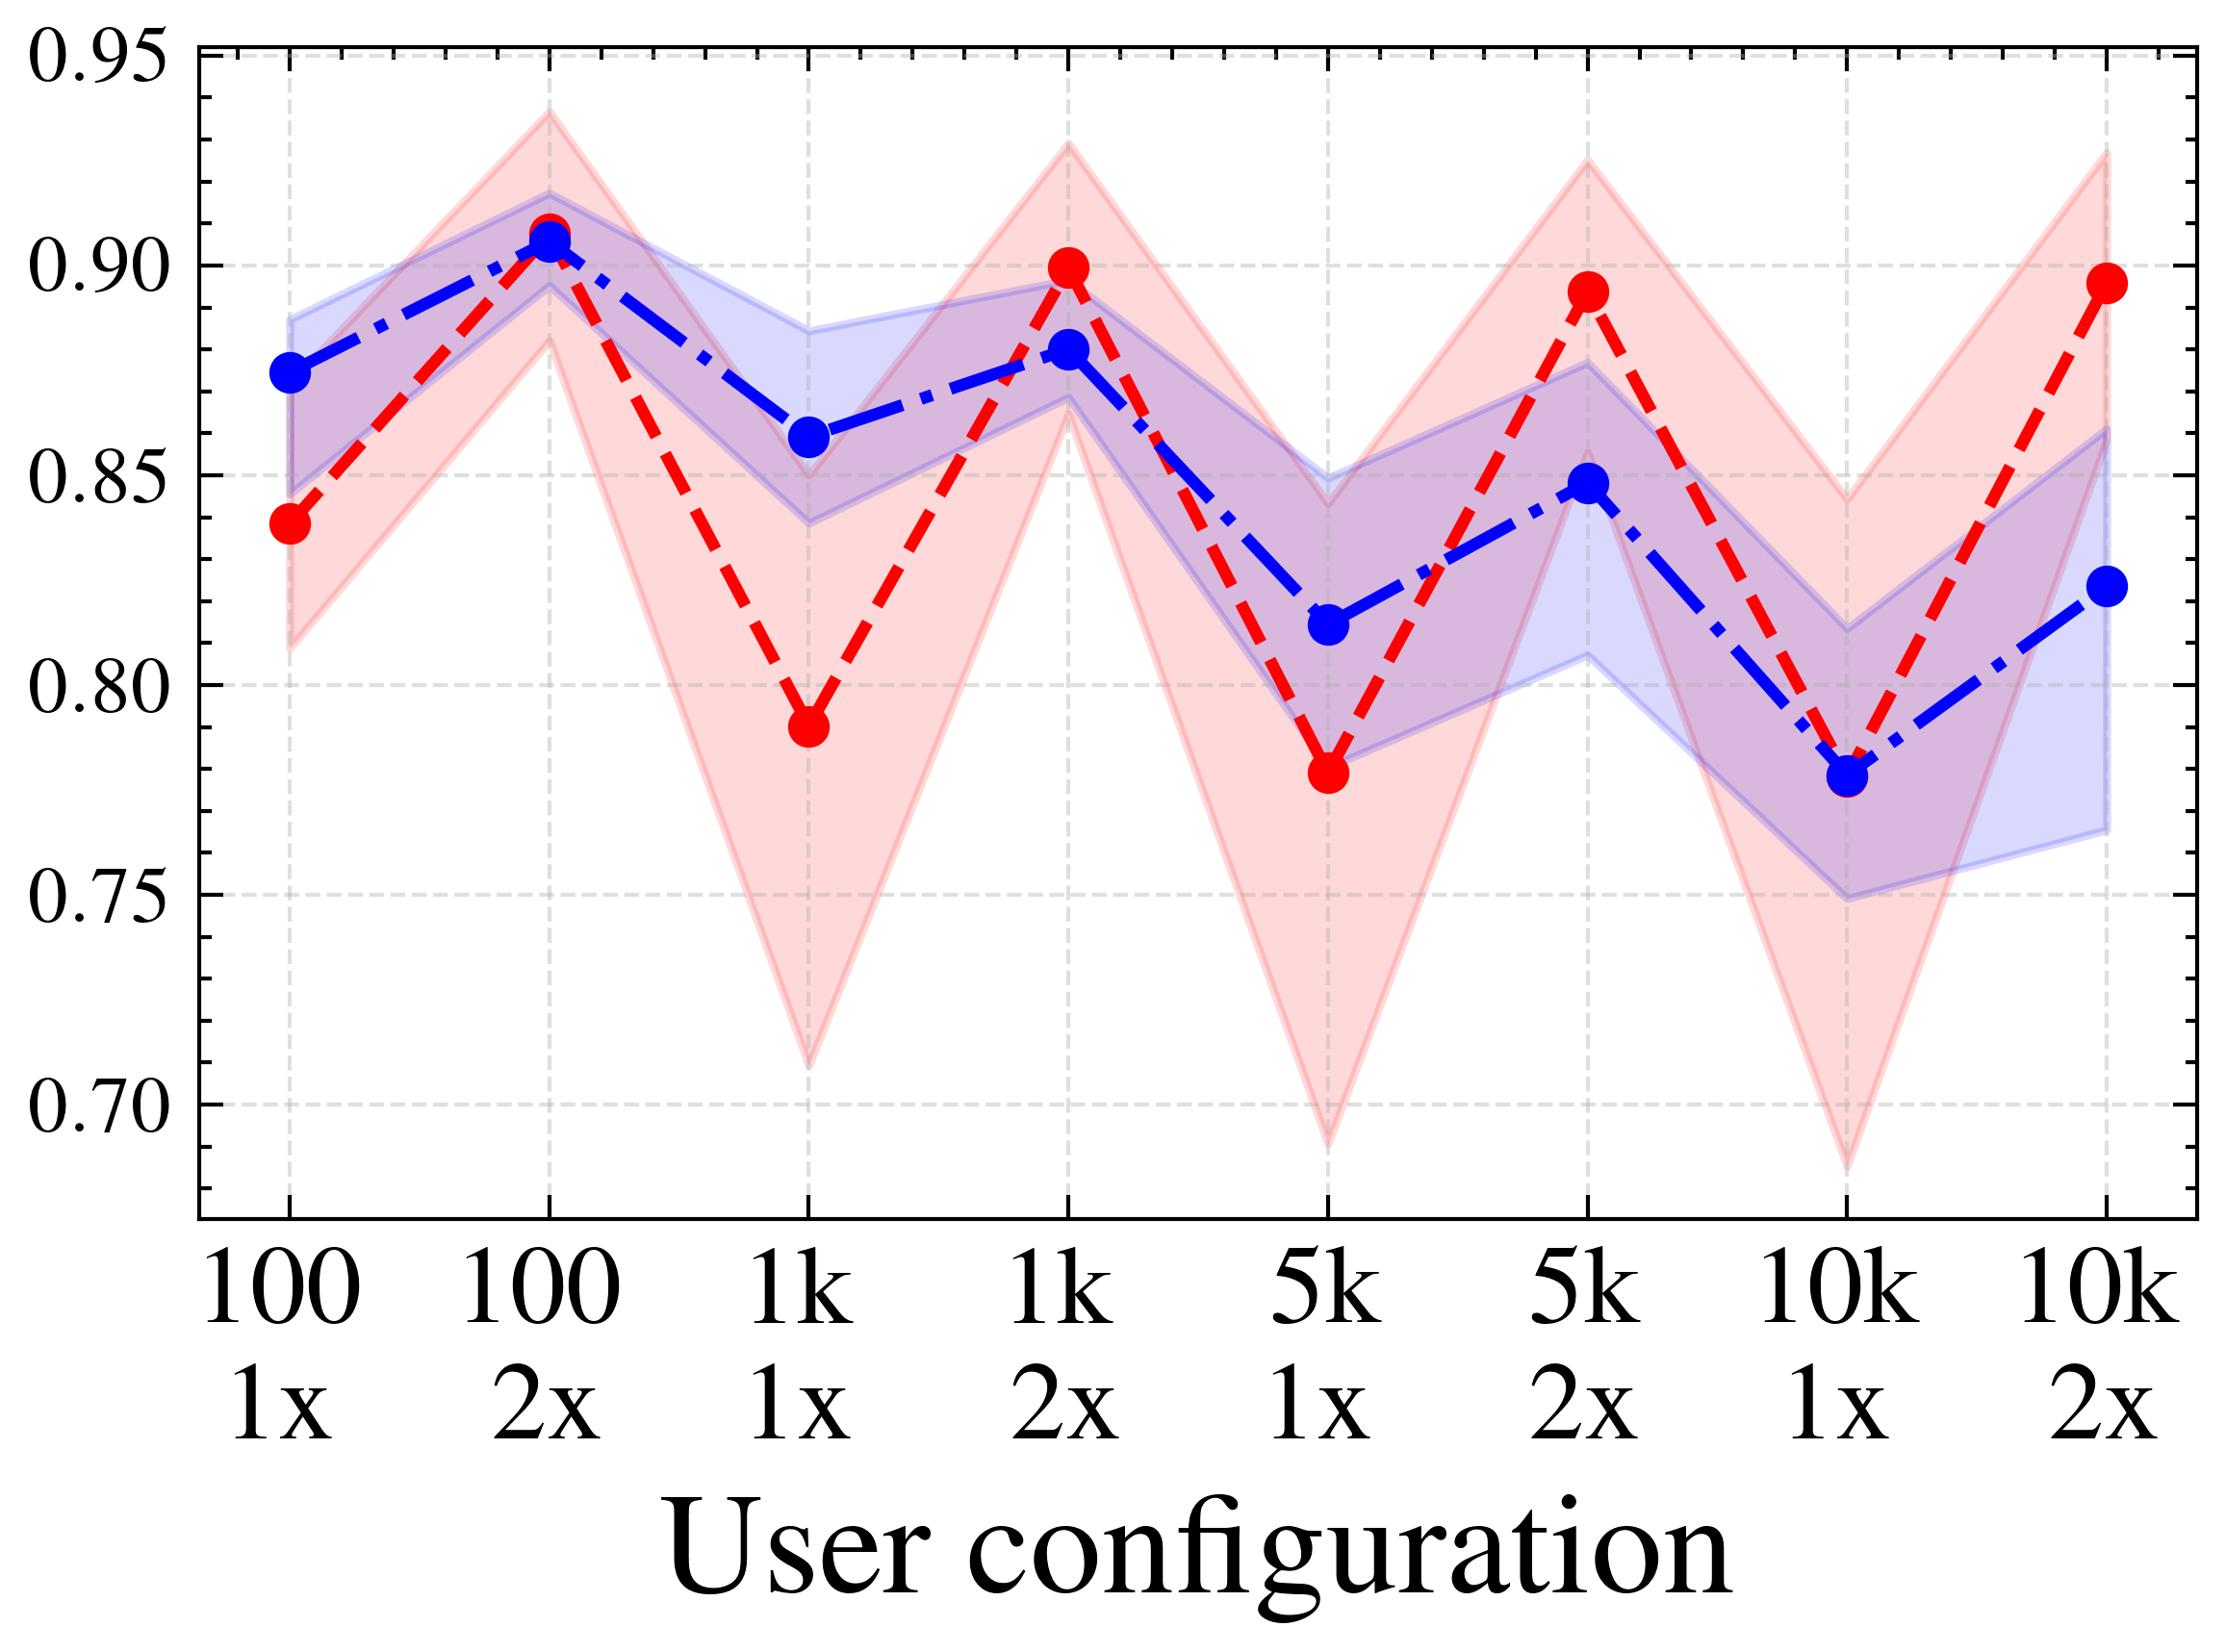

In [22]:
_theme_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
POLICY_COLORS = {policy: _theme_colors[i] for i, policy in enumerate(POLICIES)}

POLICY_LINESTYLES = {
    "centralized": "-",
    "default":     "--",
    "smart":       "-.",
    "smartx":      ":",
}

# _all_vals[(server_mult, t, policy)] = (srv_rate_vals, cli_rate_vals) over x_configs
_all_vals = {}
for server_mult in server_mults:
    for t in range(n_tasks):
        for policy in POLICIES:
            srv_rate_vals, cli_rate_vals = [], []
            for n_clients, client_mult in x_configs:
                key = (policy, server_mult, n_clients, client_mult, t)
                if key in subtask_data:
                    entries = subtask_data[key]
                    srv_rate_vals.append(np.nanmean([e[0] for e in entries]))
                    cli_rate_vals.append(np.nanmean([e[1] for e in entries]))
                else:
                    srv_rate_vals.append(np.nan)
                    cli_rate_vals.append(np.nan)
            _all_vals[(server_mult, t, policy)] = (srv_rate_vals, cli_rate_vals)

# Shared y-limits computed from data (rates are in [0, 1])
def _ylim_for(rate_idx):
    finite = [
        v
        for vals in _all_vals.values()
        for v in vals[rate_idx]
        if not np.isnan(v)
    ]
    pad = (max(finite) - min(finite)) * 0.05
    return (max(0.0, min(finite) - pad), min(1.0 + pad, max(finite) + pad))

_ylim_server = _ylim_for(0)
_ylim_client = _ylim_for(1)

# legend_loc=None means no legend on the first figure
GROUPS = [
    (0, "Server completion rate", _ylim_server, "server_subtask_rate", "lower left"),
    (1, "User completion rate", _ylim_client, "user_subtask_rate", None),
]

INSET_LOC = "lower left"  # adjust if it overlaps the lines/markers in a given figure

# Individual figures: one per group per server capacity
for rate_idx, row_label, ylim, fname_base, legend_loc in GROUPS:
    for i, server_mult in enumerate(server_mults):
        fig, ax = plt.subplots(figsize=(4, 3))

        policy_curves = {}
        for policy, policy_label in zip(POLICIES, POLICY_LABELS):
            color = POLICY_COLORS[policy]
            ls    = POLICY_LINESTYLES[policy]

            task_rates = np.array([_all_vals[(server_mult, t, policy)][rate_idx] for t in range(n_tasks)])
            mean_vals  = np.nanmean(task_rates, axis=0)
            min_vals   = np.nanmin(task_rates,  axis=0)
            max_vals   = np.nanmax(task_rates,  axis=0)
            policy_curves[policy] = (mean_vals, min_vals, max_vals)

            ax.plot(x_pos, mean_vals, color=color, linestyle=ls, marker="o",
                    markersize=4, markeredgewidth=1.2, linewidth=1.5, label=policy_label)
            ax.fill_between(x_pos, min_vals, max_vals, color=color, alpha=0.15)

        ax.set_ylim(ylim)
        ax.set_xticks(x_pos)
        ax.set_xticklabels(x_labels, fontsize=14)
        ax.tick_params(axis="y", labelsize=10)
        ax.tick_params(axis="x", which="minor", bottom=False)
        ax.set_xlabel("User configuration", fontsize=18)
        ax.grid(True, linestyle="--", alpha=0.4)

        if i == 0:
            ax.set_ylabel(row_label, fontsize=16)
            if legend_loc is not None:
                ax.legend(fontsize=13, loc=legend_loc, ncol=1)

        # Zoomed inset on this figure's own y-range, so small variations stay visible
        # even though the main (outer) y-axis stays shared across all figures in the group.
        # Only added for the server completion rate group, not the user one.
        if i > 0 and rate_idx == 0:
            inset_ax = inset_axes(ax, width="50%", height="50%", loc=INSET_LOC, borderpad=3.0)

            local_vals = np.concatenate([
                np.concatenate([mean_vals, min_vals, max_vals])
                for mean_vals, min_vals, max_vals in policy_curves.values()
            ])
            local_vals = local_vals[np.isfinite(local_vals)]
            y_span = local_vals.max() - local_vals.min()
            y_pad  = y_span * 0.1 if y_span > 0 else max(local_vals.max() * 0.05, 1e-3)
            inset_ax.set_ylim(local_vals.min() - y_pad, local_vals.max() + y_pad)

            for policy, policy_label in zip(POLICIES, POLICY_LABELS):
                color = POLICY_COLORS[policy]
                ls    = POLICY_LINESTYLES[policy]
                mean_vals, min_vals, max_vals = policy_curves[policy]

                inset_ax.plot(x_pos, mean_vals, color=color, linestyle=ls,
                               marker="o", markersize=2, markeredgewidth=0.8, linewidth=1.0)
                inset_ax.fill_between(x_pos, min_vals, max_vals, color=color, alpha=0.15)

            inset_ax.set_xticks([])
            inset_ax.tick_params(axis="y", labelsize=6)
            inset_ax.grid(True, linestyle="--", alpha=0.3)
            for spine in inset_ax.spines.values():
                spine.set_linewidth(0.6)

        fname = f"{fname_base}_{server_mult}x.pdf"
        plt.tight_layout()
        plt.savefig(os.path.join(figures_dir, fname), bbox_inches="tight")
        print(f"{row_label} — Figure {i + 1} — server {server_mult}x  →  {fname}")
        plt.show()